In [1]:
import numpy as np
import pandas as pd
import xarray as xr
import pyvista as pv
import os

import matplotlib.pyplot as plt
import matplotlib.patches as patches
from matplotlib.colors import LogNorm, Normalize

from scipy.ndimage import label, binary_erosion, binary_dilation, convolve, zoom, gaussian_filter,distance_transform_edt
from scipy.interpolate import RegularGridInterpolator
from scipy.optimize import curve_fit

import vtk
vtk.vtkObject.GlobalWarningDisplayOff()

import cavity_functions_cyclic as f

In [2]:
theta_nb_chosen = '60'
filename_chosen = 'sinus3dnS_1_14_'+theta_nb_chosen+'_0065__t0002'
path_name='../data/sinus3dnS_1_14_0065/'+filename_chosen+'.csv'
data_chosen=pd.read_csv(path_name)

#by default : 
threshold = 0.15 #m 
threshold_list = [0.01]#np.arange(0.197,0.203,0.001)
cavitation_pressure_list = np.arange(46,81,1)


for limit in threshold_list :
    for theta in cavitation_pressure_list :
        theta_nb = str(theta)
        if len(theta_nb) ==1 :
            theta_nb = '0'+ theta_nb
        tmp_filename = 'sinus3dnS_1_14_'+theta_nb+'_0065__t0002'
        tmp_path_name='../data/sinus3dnS_1_14_0065/'+tmp_filename+'.csv'
        tmp_data=pd.read_csv(tmp_path_name)
        data1, data_filtered1 = f.filter_data(tmp_data,threshold=limit,file_name=tmp_filename,save=False,clip=False,rolling=False)
        data, data_filtered = f.filter_data(data_filtered1,threshold=limit,file_name=tmp_filename,save=False,clip=False,rolling=False)
        if ((data_filtered.cavity_status.values) == -1 ).all():
            continue
            #print(f'at theta={theta_nb} No valid cavity for threshold={threshold}\n')
        else : 
            print(f'the first valid cavity for threshold={limit} is at theta={theta_nb}\n ')
            break


# Some pre - processing

In [3]:
# compute the cavitation from the stress field.
def compute_cavitation(data_c,theta_nb_c):

    m=3
    h_r = data_chosen['bedrock'].std() 
    rho_i = 920
    g = 9.81
    
    tau_b_chosen = np.abs(data_c['stress vector_0']*1e6).mean() # from Mpa to Pa
    U_b_chosen = (data_c['velocity_0']/365.25/86400).mean()     # from m/a to m/s
    
    tau_b_0_pow_m_list = []
    U_b_0_list = []
    
    zero_cavitation_pressure_list = np.arange(0,1,1) # overburden pressure ratio settings for which there is no cavitation, here we consider this True for ovb_ratio = 0 only
    for theta in zero_cavitation_pressure_list :
        theta_nb = str(theta)
        if len(theta_nb) ==1 :
            theta_nb = '0'+ theta_nb
        tmp_filename = 'sinus3dnS_1_14_'+theta_nb+'_0065__t0002'
        tmp_path_name='../data/sinus3dnS_1_14_0065/'+tmp_filename+'.csv'
        tmp_data=pd.read_csv(tmp_path_name)
        tau_b_0_pow_m_list.append(pow(np.abs(tmp_data['stress vector_0']*1e6).mean(),m))
        U_b_0_list.append((tmp_data['velocity_0']/365.25/86400).mean())

    # when there is no cavitation we can infer A_s :
    A_s = (np.array(U_b_0_list)/np.array(tau_b_0_pow_m_list)).mean() # we consider cavitation = 0. 
    #A_s = 6.8083e-26
    
    print(f'The found A_s is : {A_s:.4e} m s⁻¹ Pa^(-m)')
    
    if int(theta_nb_chosen) in zero_cavitation_pressure_list :
        real_cavitation_chosen = 0
    else :
        real_cavitation_chosen = 1 - (tau_b_chosen**m * A_s/U_b_chosen)


    N_norm_chosen = (1-int(theta_nb)/100) # N = Pi - Pw = Pi (1 - theta_nb ) ~ (1 - theta_nb )

    # get all the K_pi/pw
    known_cavitation_pressure_list = np.arange(0,81,1)  # overburden pressure ratio settings for which there is a water discharge/path.
    
    real_cavitation_list = []
    cavitation_from_Gilbert_list = []
    N_norm_list = []
    tau_b_list  = []
    U_b_list    = []
    h_list      = []
    for theta in known_cavitation_pressure_list :
        theta_nb = str(theta)
        if len(theta_nb) ==1 :
            theta_nb  = '0'+ theta_nb
        tmp_filename  = 'sinus3dnS_1_14_'+theta_nb+'_0065__t0002'
        tmp_path_name = '../data/sinus3dnS_1_14_0065/'+tmp_filename+'.csv'
        tmp_data = pd.read_csv(tmp_path_name)
        tau_b = np.abs(tmp_data['stress vector_0']*1e6).mean()
        U_b   = (tmp_data['velocity_0']/365.25/86400).mean()
        U_b_list.append(U_b)
        tau_b_list.append(tau_b)
        N_norm = (1-int(theta_nb)/100)*rho_i*g*200
        N_norm_list.append(N_norm)
    
        h_list.append(tmp_data.hcavity.mean())
        
        real_cavitation = 1 - (tau_b**m * A_s/U_b) # as defined in (1) Gilbert & al 2022
        cavitation_state_from_G = (tmp_data.hcavity.mean()/h_r)**(1/0.6)  # as defined in (8) Gilbert & al 2022
        cavitation_from_Gilbert_list.append(cavitation_state_from_G)
        real_cavitation_list.append(real_cavitation)


    plt.plot(known_cavitation_pressure_list,real_cavitation_list,'o-',label='from stress (eq1)')
   # plt.plot(known_cavitation_pressure_list,cavitation_from_Gilbert_list,label='from hcavity (eq8)')
    plt.axvline(int(theta_nb_c),linestyle='--', label=f'overburden ratio : {theta_nb_c}')
    plt.axhline(real_cavitation_list[int(theta_nb_c)],linestyle='--', label=f'cavitation : {real_cavitation_list[int(theta_nb_c)]:.2f}')

    plt.xlabel(r'$K_{Pw/Pi}$')
    plt.ylabel(r'taux de cavitation $\theta$')
    plt.ylim(0.0,1.1)
    plt.legend()

    dic_values = {'h': h_list, 'N_norm': N_norm_list, 'tau_b': tau_b_list, 'U_b': U_b_list, 'Cavitation_from_eq8' : cavitation_from_Gilbert_list}

    return real_cavitation_chosen, real_cavitation_list, dic_values, tau_b_chosen, A_s


The found A_s is : 3.8465e-20 m s⁻¹ Pa^(-m)


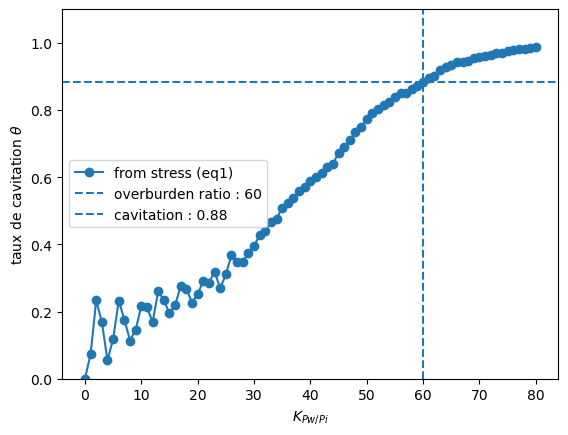

In [4]:
real_cavitation_chosen, real_cavitation_list, all_the_other_values, tau_b_chosen, A_s = compute_cavitation(data_chosen,theta_nb_chosen)

In [22]:
h_r = data_chosen['bedrock'].std()
A_s =  3.8465e-20
rho_i = 920
g = 9.81

N = (1-int(theta_nb_chosen)/100)*rho_i*g*200
a_list_from_schoof = np.array(all_the_other_values['tau_b'])**3 *A_s*h_r / ( (1-np.array(real_cavitation_list))*2*2.5e-24*3**-3*np.array(all_the_other_values['N_norm'])**3 )

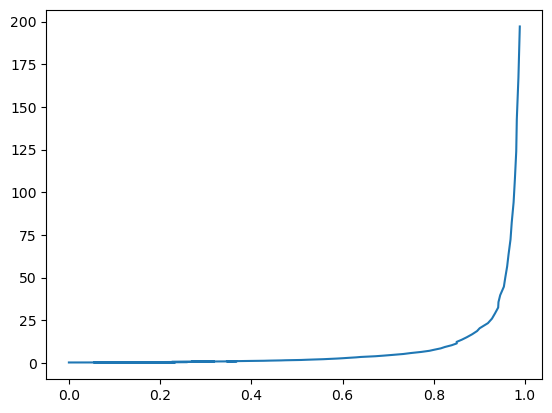

In [23]:
plt.plot(real_cavitation_list,a_list_from_schoof)

In [80]:
a_list_from_schoof[65]

np.float64(0.47492885952890956)

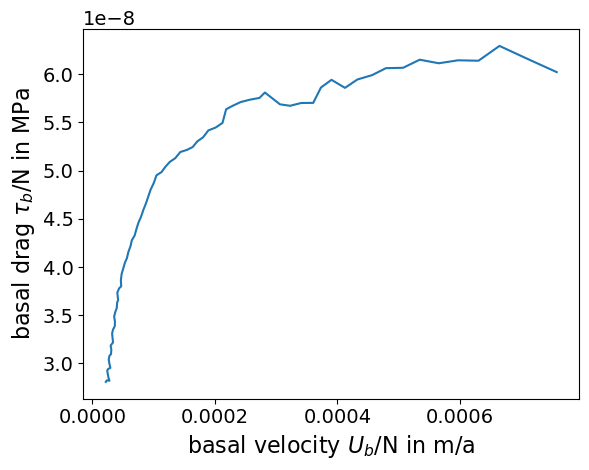

In [81]:
plt.plot(np.array(all_the_other_values['U_b'])*365.25*86400/np.array(all_the_other_values['N_norm']),np.array(all_the_other_values['tau_b'])/1e6/np.array(all_the_other_values['N_norm']))
plt.xlabel(r'basal velocity $U_b$/N in m/a')
plt.ylabel(r'basal drag $\tau_b$/N in MPa')
plt.show()

# FILTER THE CSV :

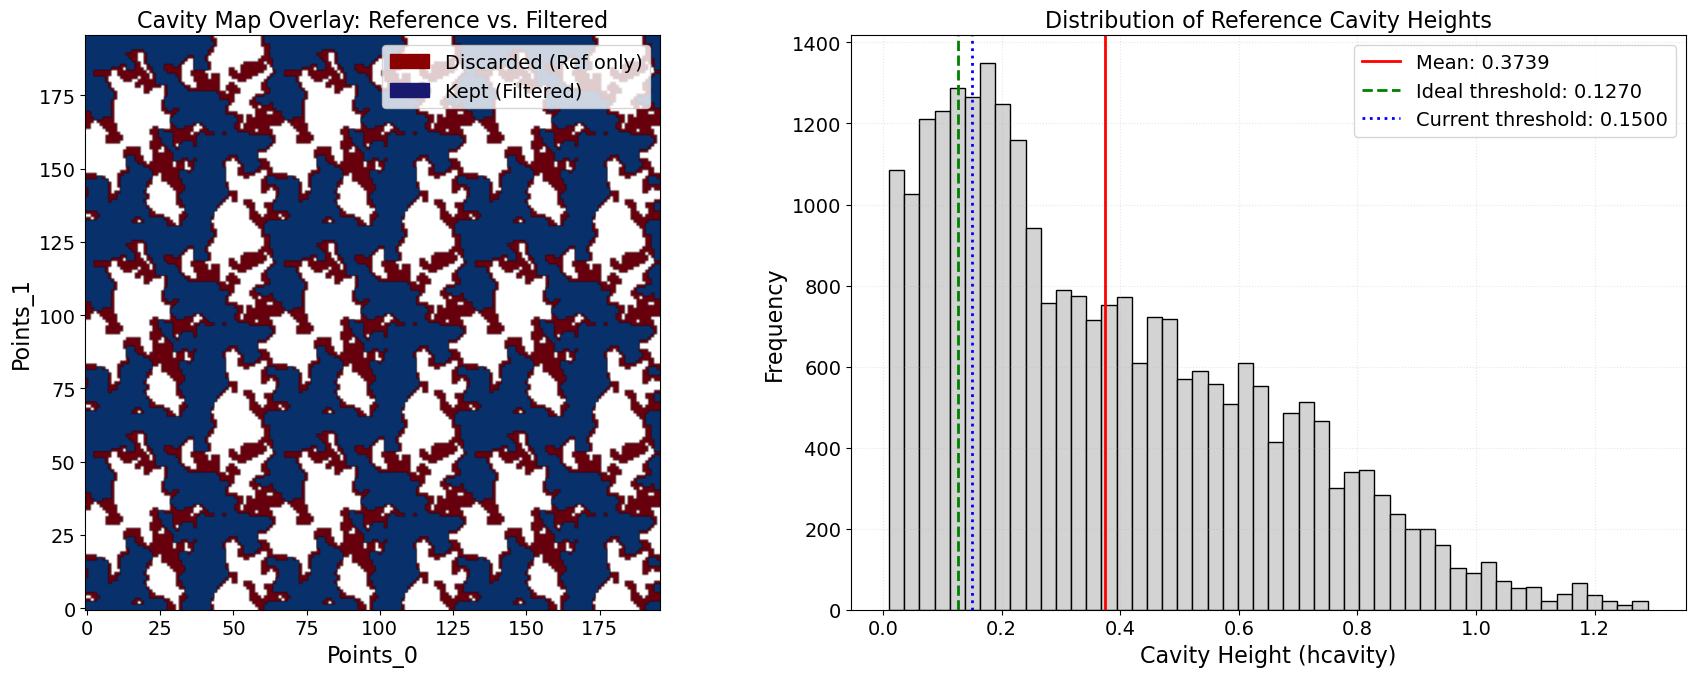

--- Cavity Height Statistics ---
Mean : 0.37393 m
Std  : 0.26773 m
Suggested Ideal Threshold :  0.12699 m , which keeps 80% of the data points.
Currently, the Threshold keeps 76% of the data points.

--- Spatial Footprint (Area) ---
Reference pixels: 26440
Filtered pixels:  17473
Spatial footprint Kept:      66.1%


In [82]:
    # data filtering

data, data_filtered = f.filter_data(data_chosen, threshold=threshold, file_name=filename_chosen, save=False, clip=False, rolling=False)

#switch to ds, as its easier to handle :
ds_cavity = data_filtered.set_index(['Points_1', 'Points_0']).sort_index().to_xarray()
ds_cavity['cavity_status'] = xr.where(ds_cavity['cavity_status'] >= 0, 1, np.nan)

# filtering of the same data with a 1cm threshold for reference :
data_ref, data_filtered_ref = f.filter_data(data_chosen, threshold=0.01, file_name=filename_chosen, save=False, clip=False, rolling=False)

ds_cavity_ref = data_filtered_ref.set_index(['Points_1', 'Points_0']).sort_index().to_xarray()
ds_cavity_ref['cavity_status'] = xr.where(ds_cavity_ref['cavity_status'] >= 0, 1, np.nan)

cavity_ref_df = data_filtered_ref[data_filtered_ref['cavity_status'] >= 0].copy()


    # a few stats :
# Extract the cavity heights from the reference dataset, dropping nans
h_cavity_data = cavity_ref_df['hcavity'].dropna()

mean_h = h_cavity_data.mean()
std_h = h_cavity_data.std()
perc_discarded = 0.2
ideal_threshold = h_cavity_data.quantile(perc_discarded)


    # plotting
fig, axes = plt.subplots(1, 2, figsize=(18, 7))

# Plot 1 : visual overlay of cavity maps
ax1 = axes[0]

# Plot the full reference (threshold 0.01) as the base layer in Red:
ax1.imshow(ds_cavity_ref['cavity_status'], cmap='Reds_r', origin='lower')

# Plot the filtered data on top in Blue:
ax1.imshow(ds_cavity['cavity_status'], cmap='Blues_r', origin='lower')

# Create legend :
red_patch = patches.Patch(color='darkred', label='Discarded (Ref only)')
blue_patch = patches.Patch(color='midnightblue', label='Kept (Filtered)')
ax1.legend(handles=[red_patch, blue_patch], loc='upper right')

ax1.set_title('Cavity Map Overlay: Reference vs. Filtered')
ax1.set_xlabel('Points_0')
ax1.set_ylabel('Points_1')
ax1.set_box_aspect(1)

# Plot 2: Statistical Distribution of hcavity
ax2 = axes[1]

ax2.hist(h_cavity_data, bins=50, color='lightgray', edgecolor='black')

# put statistical markers
ax2.axvline(mean_h, color='red', linestyle='-', linewidth=2, label=f'Mean: {mean_h:.4f}')
ax2.axvline(ideal_threshold, color='green', linestyle='--', linewidth=2, label=f'Ideal threshold: {ideal_threshold:.4f}')
ax2.axvline(threshold, color='blue', linestyle=':', linewidth=2, label=f'Current threshold: {threshold:.4f}')

ax2.set_title('Distribution of Reference Cavity Heights')
ax2.set_xlabel('Cavity Height (hcavity)')
ax2.set_ylabel('Frequency')
ax2.legend()
ax2.grid(alpha=0.3, linestyle=':')

plt.tight_layout()
plt.show()


current_quantile = (h_cavity_data <= threshold).mean()

# compute the spatial footprint reduction (pixel counts)
ref_pixel_count = int(ds_cavity_ref['cavity_status'].count().item())
filtered_pixel_count = int(ds_cavity['cavity_status'].count().item())

spatial_kept_pct = (filtered_pixel_count / ref_pixel_count) * 100 if ref_pixel_count > 0 else 0

print(f"--- Cavity Height Statistics ---")
print(f"Mean : {mean_h:.5f} m")
print(f"Std  : {std_h:.5f} m")
print(f"Suggested Ideal Threshold :  {ideal_threshold:.5f} m , which keeps {(1-perc_discarded)*100:.0f}% of the data points.")
print(f"Currently, the Threshold keeps {(1-current_quantile)*100:.0f}% of the data points.\n")

print(f"--- Spatial Footprint (Area) ---")
print(f"Reference pixels: {ref_pixel_count}")
print(f"Filtered pixels:  {filtered_pixel_count}")
print(f"Spatial footprint Kept:      {spatial_kept_pct:.1f}%")

In [83]:
knobin =  [16,-25] # [2,-48]
data, data_filtered = f.filter_data(data_chosen, threshold=threshold, file_name=filename_chosen, save=False, clip=False, rolling=True, knob_Pts=knobin)
# knobin for 80 h_lim=0.25 : [1,0]
# for 70 h_lim=0.2  : [27,0], h_lim =0.1 :[23,5], h_lim =0.15 : [2,-48]
# for 57,60 h_lim=0.15 : [16,-25]
# for 65, h_lim=0.15 : [11,-18]
# for 75, h_lim=0.15 : [27,18]
# for 80, h_lim=0.15 : [-9,20] ou [17,20] actuellement

In [84]:
ds_filtered = data_filtered.set_index(['Points_1', 'Points_0']).sort_index().to_xarray()
ds_filtered = ds_filtered.sel(Points_1=slice(13, 2*13), Points_0=slice(13, 2*13))
ds_filtered = ds_filtered.where(ds_filtered['cavity_status'] >= 0)

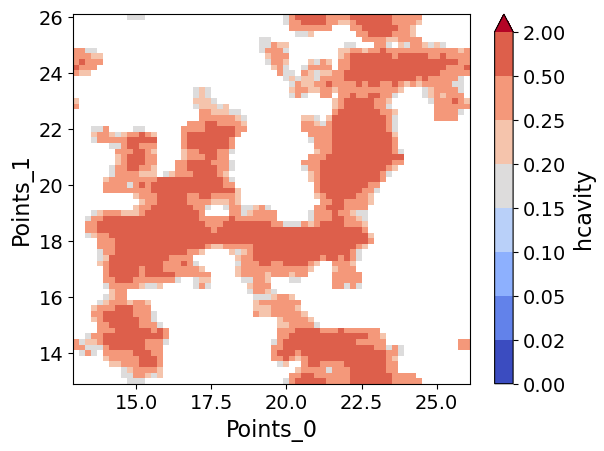

In [85]:
ds_filtered['hcavity'].plot(cmap='coolwarm',levels=[0,0.02,0.05,0.1,0.15,0.2,0.25,0.5,2],extend='max')

# Create the .stl

In [86]:
# file name automation for saving : 
trsh_str = str(int(threshold*100))
file_name=filename_chosen+'_trsh_'+trsh_str
print(file_name)

sinus3dnS_1_14_60_0065__t0002_trsh_15


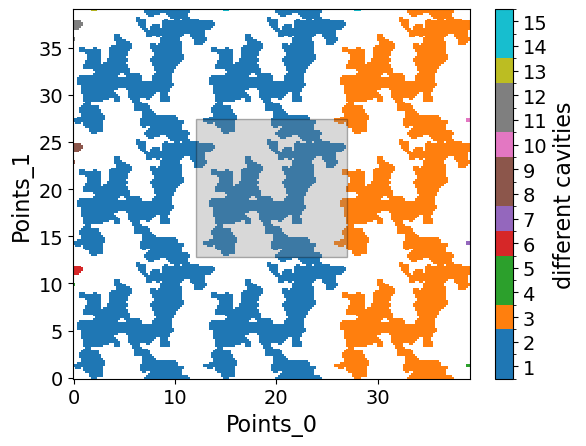

is this domain correct ? y/n ?
[12.0, 27.0, 12.8, 27.4]


 n


enter the desired domain coordinates : x_min x_max y_min y_max] :


Enter numbers separated by space:  19.0 27.0 12.80 27.40


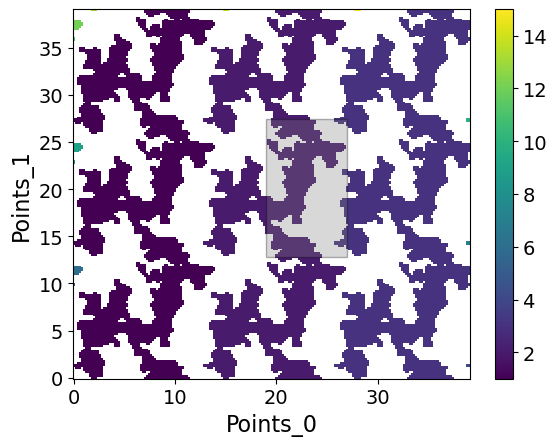

is this domain correct ? y/n ? 


 n


enter the desired domain coordinates : x_min x_max y_min y_max] :


Enter numbers separated by space:  18.60 27.0 12.80 27.40


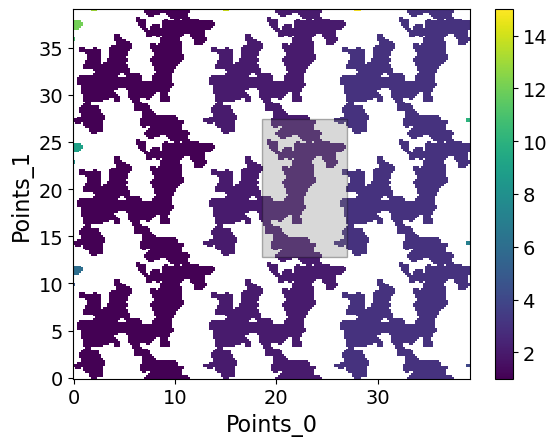

is this domain correct ? y/n ? 


 n


enter the desired domain coordinates : x_min x_max y_min y_max] :


Enter numbers separated by space:  18.60 25.0 12.80 27.40


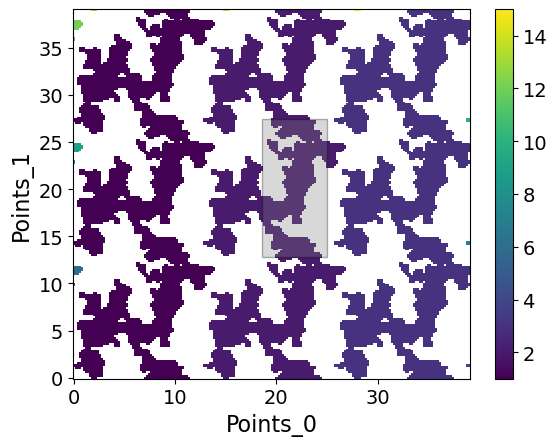

is this domain correct ? y/n ? 


KeyboardInterrupt: Interrupted by user

In [87]:
                 #[x_min,x_max,y_min,y_max]
box_coords_setup =[12.0, 27.0, 12.80, 27.40] #[12.4, 26.6, 13.0, 26.0]  #

body_dic, b_coords, ds_test = f.create_surface_mesh(data_filtered,b_coords = box_coords_setup,save=True, file_name=file_name, threshold=threshold,choose_1_body=False)

/tmp/ipykernel_6180/8119094.py:5: UserWarning: Using static image for notebook display.
Install trame for interactive backends: pip install "pyvista[jupyter]"
  pl.show()


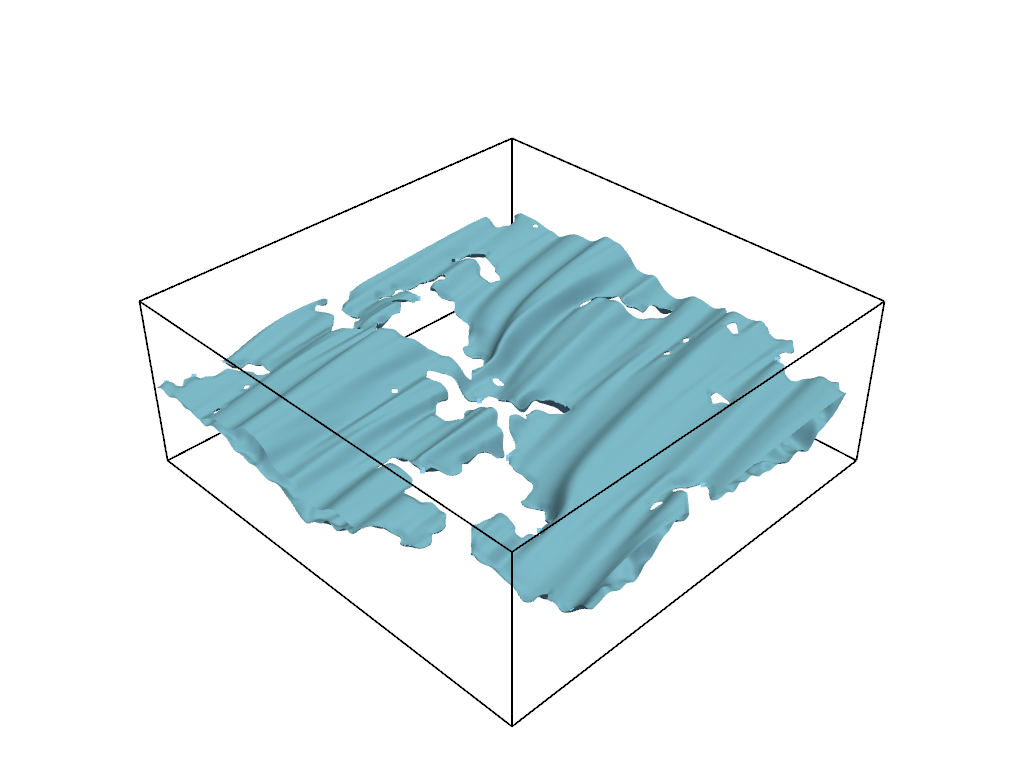

In [77]:
pl = pv.Plotter()
actor = pl.add_mesh(pv.Cube(bounds=(b_coords[0],b_coords[1],b_coords[2],b_coords[3],-2.5,2.5)),color='black',style='wireframe',line_width=2)
actor = pl.add_mesh(body_dic[0]['AOI_surface_walls'], color='skyblue')
#actor = pl.add_mesh(body_dic[1]['surface_walls'], color='lightblue')
pl.show()

In [14]:
boundaries_values,k, omega = f.turbulent_initialisation(body_dic,b_coords,inlet='y_min')

NameError: name 'body_dic' is not defined

In [15]:
boundaries_values['y_min']['area']

NameError: name 'boundaries_values' is not defined

In [16]:
boundaries_values['y_max']['perimeter'] == boundaries_values['y_min']['perimeter']

NameError: name 'boundaries_values' is not defined

# CFD pre-processing

In [5]:
def initialisation_correc_for_60():
    rho_w             = 1000 # kg/m3
    rho_i             = 920  # kg/m3
    H                 = 100  # m
    g                 = 9.81 # m/s2
    overburden_ratio  = 0.7  # adim
    basal_slope       = 5    # degrees°
    domain_length_L   = 14.6   # m

    P_R_channel       = 0    # Pa
    dist_to_R_channel = 100  # m

    basal_slope = np.deg2rad(basal_slope)
    
    P_i     = rho_i * g * H           # Pa
    P_inlet = overburden_ratio * P_i  # Pa
    
    delta_z = domain_length_L * np.sin(basal_slope)

    delta_P_w_min = 0 # Pa
    delta_phi_min = rho_w*g*delta_z + delta_P_w_min  # Pa
    grad_eff_phi_min = delta_phi_min/domain_length_L # Pa/m
    
    # the water pressure gradient between the inlet and the R-channel :
    grad_P_w = (P_inlet-P_R_channel)/dist_to_R_channel
    
    delta_P_w_max = grad_P_w * domain_length_L

    delta_phi_max = rho_w*g*delta_z + delta_P_w_max
    grad_eff_phi_max = delta_phi_max/domain_length_L
    
    grad_eff_phi_list = np.linspace(grad_eff_phi_min,grad_eff_phi_max,10)
    
    # we add 3 more extreme values to the list : 
    # 2 low grad :
    delta_P_w= np.array([1.5,5.5])
    delta_phi = rho_w*g*delta_z + delta_P_w*rho_w  # Pa
    grad_eff_phi = delta_P_w*1000/domain_length_L # Pa/m
    # 1 extreme grad :
    tmp_float=(rho_w*g*delta_z + (631.76-500.0)*rho_w)/domain_length_L 
    # gymnastic to append each value on the appropriate side :
    tmp = np.append(grad_eff_phi_list,tmp_float)
    grad_eff_phi_list=np.append(grad_eff_phi , tmp)

    
    kinematic_P_outlet_list  = [] # m2/s2
    print(f'P_inlet/rho_w = {(P_inlet)/rho_w:.2f} m2/s2\n')
    for grad_eff_phi in grad_eff_phi_list :
        
        P_outlet=(P_inlet-grad_eff_phi*domain_length_L)
        kinematic_P_outlet_list.append(P_outlet/rho_w)
        print(f'  P_outlet/rho_w = {(P_outlet)/rho_w:.2f}  m2/s2\n    grad_eff_phi = {grad_eff_phi:.2f} Pa/m \n\n')

    return kinematic_P_outlet_list, grad_eff_phi_list


In [6]:
kinematic_P_outlet_list, grad_eff_phi_list = f.initialisation()
# For 60 L != 13 but 14.6, so grad phi eff is slightly different : 
kinematic_P_outlet_list_for_60, grad_eff_phi_list_for_60 = initialisation_correc_for_60()


Kp_inlet = 631.76 #m2/s2

P_inlet/rho_w = 631.76 m2/s2

  P_outlet/rho_w = 630.26  m2/s2
    grad_eff_phi = 115.38 Pa/m 


  P_outlet/rho_w = 626.26  m2/s2
    grad_eff_phi = 423.08 Pa/m 


  P_outlet/rho_w = 620.65  m2/s2
    grad_eff_phi = 855.00 Pa/m 


  P_outlet/rho_w = 611.52  m2/s2
    grad_eff_phi = 1556.96 Pa/m 


  P_outlet/rho_w = 602.40  m2/s2
    grad_eff_phi = 2258.92 Pa/m 


  P_outlet/rho_w = 593.27  m2/s2
    grad_eff_phi = 2960.88 Pa/m 


  P_outlet/rho_w = 584.15  m2/s2
    grad_eff_phi = 3662.84 Pa/m 


  P_outlet/rho_w = 575.02  m2/s2
    grad_eff_phi = 4364.80 Pa/m 


  P_outlet/rho_w = 565.90  m2/s2
    grad_eff_phi = 5066.76 Pa/m 


  P_outlet/rho_w = 556.77  m2/s2
    grad_eff_phi = 5768.72 Pa/m 


  P_outlet/rho_w = 547.65  m2/s2
    grad_eff_phi = 6470.68 Pa/m 


  P_outlet/rho_w = 538.52  m2/s2
    grad_eff_phi = 7172.64 Pa/m 


  P_outlet/rho_w = 488.89  m2/s2
    grad_eff_phi = 10990.38 Pa/m 


P_inlet/rho_w = 631.76 m2/s2

  P_outlet/rho_w = 630.26  m2/s2
    grad_eff_phi = 102.74

In [7]:
f'{kinematic_P_outlet_list[2]:.2f}'

'620.65'

# Post-processing

In [112]:
# setup to post-process :
theta_nb_pp = "60"#theta_nb_chosen
trsh_str_pp = '15'#trsh_str
P_outlet_index = -1
P_out_val_pp=str(f'_kPout_{kinematic_P_outlet_list[P_outlet_index]:.0f}')

cavitation_val = real_cavitation_list[int(theta_nb_pp)]

file_name_pp = f'sinus3dnS_1_14_{theta_nb_pp}_0065__t0002_trsh_{trsh_str_pp}'


file_name_post = file_name_pp+P_out_val_pp
print(file_name_post)
directory_name_pp=f'3D_cavity_{theta_nb_pp}_trsh_{trsh_str_pp}'+P_out_val_pp
print(directory_name_pp)

sinus3dnS_1_14_60_0065__t0002_trsh_15_kPout_489
3D_cavity_60_trsh_15_kPout_489


Error: Could not find /home/grandafe/OpenFOAM/grandafe-v2412/run/60/trsh_15/3D_cavity_60_trsh_15_kPout_489/postProcessing/outletFlowRate//6000/surfaceFieldValue.dat


(6000.0, 9000.0)

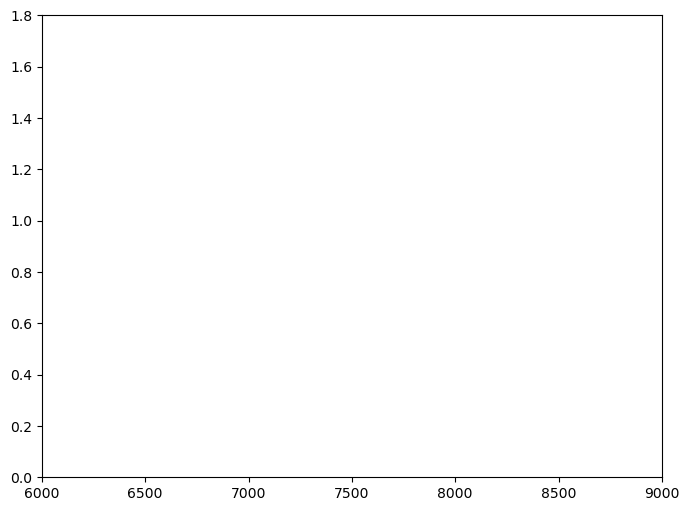

In [113]:
flowrate_df = f.get_flow_rates(directory_name_pp,theta_nb_pp,trsh_str_pp,P_out_val_pp,merge = True,files_to_merge=[6000,9000],start_Time='6000')
mean_flow=flowrate_df[flowrate_df['Time'] >=14900][f'FlowRate{P_out_val_pp}'].mean()

fig, ax = plt.subplots(figsize=(8, 6))
flowrate_df[flowrate_df['Time'] >=00][f'FlowRate{P_out_val_pp}'].plot(ax=ax,x='Time')
plt.axhline(mean_flow,color='b')
plt.ylim(0,1.8)
plt.xlim(6000,9000)

In [114]:
mean_flow

nan

In [115]:
if trsh_str_pp == '25' :
    b_coords = [13.0, 26.0, 0.0, 26.0]
    L = 13.0
elif trsh_str_pp == '15' and  theta_nb_pp == "60":
    b_coords = [12.0, 27.0, 12.8, 27.4]
    L = 14.6
elif trsh_str_pp == '15' and  theta_nb_pp == "57":
    b_coords = [12.4, 26.6, 13.0, 26.0]
    L = 13.0
else :
    b_coords = [13.0, 26.0, 13.0, 26.0]
    L = 13.0
ds_masked, ds_2d, of_mesh = f.get_sim_data(directory_name_pp,theta_nb_pp,trsh_str_pp,b_coords,save=False,mean_val=True,yPlus=False,res=0.05,filename_save=file_name_post)

2026-08-24 16:48:29.071 (13916.250s) [        2035D740]RuntimeDeviceInformatio:234   WARN| Initializing 'RuntimeDeviceConfigurations' with uninitialized configOptions. Did you call viskores::cont::Initialize?


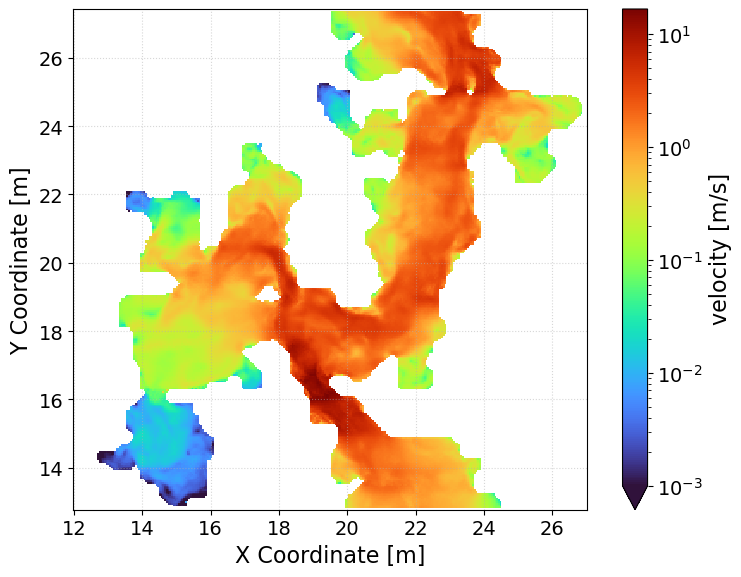

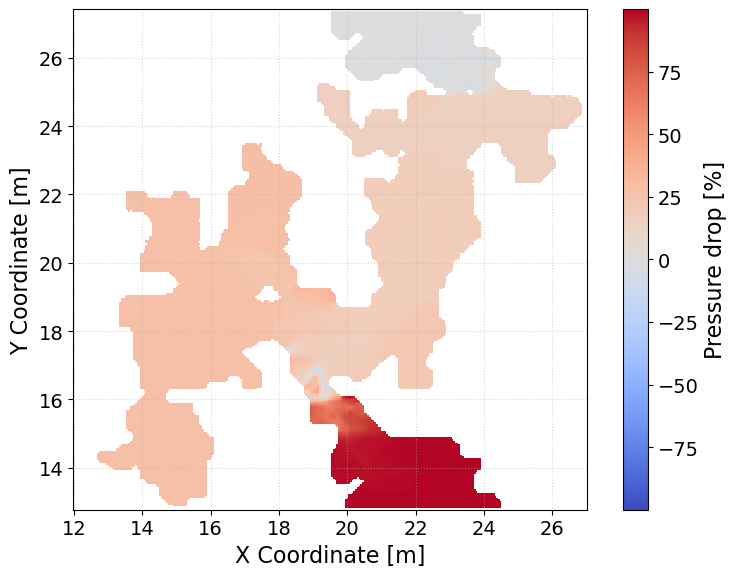

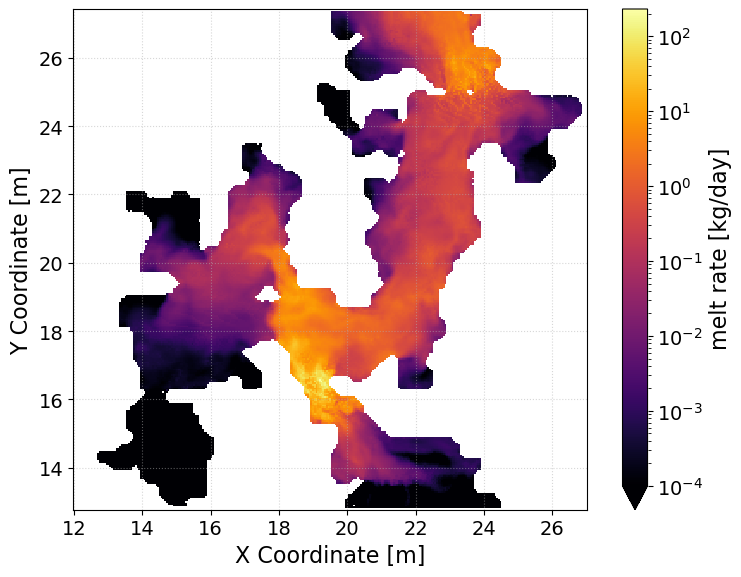

In [116]:
mean_val = False
plt.rcParams.update({
    'font.size': 14,          # General text size
    'axes.labelsize': 16,     # X and Y axis labels
    'axes.titlesize': 16,     # Main title
    'xtick.labelsize': 14,    # X tick markings
    'ytick.labelsize': 14,    # Y tick markings
})


if mean_val :
    data_to_plot = ds_2d['U_mean']
else :
    data_to_plot = ds_2d['U']


fig, ax = plt.subplots(figsize=(8, 6))

quadmesh = data_to_plot.plot(
    ax=ax,
    x='x',                                
    y='y',
    cmap='turbo',                      
    
    # LOGSCALE HANDLING:
    norm=LogNorm(vmin=1e-3, vmax=float(data_to_plot.max())), 
    
    cbar_kwargs={'label': 'velocity [m/s]'}
)
ax.set_aspect('equal')

ax.set_xlabel("X Coordinate [m]")
ax.set_ylabel("Y Coordinate [m]")

ax.grid(True, linestyle=':', alpha=0.5)

plt.tight_layout()
#plt.savefig(f'/home/grandafe/Documents/Stage/img/report/{theta_nb_pp}/U_map{P_out_val_pp}_{theta_nb_pp}.png', bbox_inches='tight') 
plt.show()


# ---------------------------------------------------------------------------------------------

"""
plt.rcParams.update({
    'font.size': 14,          # General text size
    'axes.labelsize': 16,     # X and Y axis labels
    'axes.titlesize': 16,     # Main title
    'xtick.labelsize': 14,    # X tick markings
    'ytick.labelsize': 14,    # Y tick markings
})


if mean_val :
    data_to_plot = ds_2d['k_mean']
else :
    data_to_plot = ds_2d['k']


fig, ax = plt.subplots(figsize=(8, 6))

quadmesh = data_to_plot.plot(
    ax=ax,
    x='x',                                
    y='y',
    cmap='inferno',                      
    
    # LOGSCALE HANDLING:
    norm=LogNorm(vmin=1e-3, vmax=float(data_to_plot.max())), 
    
    cbar_kwargs={'label': 'TKE [J/kg]'}
)
ax.set_aspect('equal')

ax.set_xlabel("X Coordinate [m]")
ax.set_ylabel("Y Coordinate [m]")

ax.grid(True, linestyle=':', alpha=0.5)

plt.tight_layout()
#plt.savefig('/home/grandafe/Documents/Stage/img/point_23_06/komega_map_kPout_620.png', bbox_inches='tight') 
plt.show()

"""
# ---------------------------------------------------------------------------------------------


plt.rcParams.update({
    'font.size': 14,          # General text size
    'axes.labelsize': 16,     # X and Y axis labels
    'axes.titlesize': 16,     # Main title
    'xtick.labelsize': 14,    # X tick markings
    'ytick.labelsize': 14,    # Y tick markings
})


if mean_val :
    data_to_plot = (ds_2d['p_mean']  - kinematic_P_outlet_list[P_outlet_index])/(Kp_inlet- kinematic_P_outlet_list[P_outlet_index]) *100 
else :
    data_to_plot = (ds_2d['p']  - kinematic_P_outlet_list[P_outlet_index])/(Kp_inlet- kinematic_P_outlet_list[P_outlet_index]) *100 

fig, ax = plt.subplots(figsize=(8, 6))

quadmesh = data_to_plot.plot(
    ax=ax,
    x='x',                                
    y='y',
    cmap='coolwarm', 
    #levels=[-50,-25,-5,0,5,25,50,100],extend='max',
    
    # LOGSCALE HANDLING:
    #norm=LogNorm(vmin=1e-3, vmax=float(data_to_plot.max())), 
    
    cbar_kwargs={'label': 'Pressure drop [%]'}
)
ax.set_aspect('equal')

ax.set_xlabel("X Coordinate [m]")
ax.set_ylabel("Y Coordinate [m]")

ax.grid(True, linestyle=':', alpha=0.5)

plt.tight_layout()
#plt.savefig(f'/home/grandafe/Documents/Stage/img/report/{theta_nb_pp}/P_drop_map{P_out_val_pp}_{theta_nb_pp}.png', bbox_inches='tight') 
plt.show()



# ---------------------------------------------------------------------------------------------




plt.rcParams.update({
    'font.size': 14,          # General text size
    'axes.labelsize': 16,     # X and Y axis labels
    'axes.titlesize': 16,     # Main title
    'xtick.labelsize': 14,    # X tick markings
    'ytick.labelsize': 14,    # Y tick markings
})


if mean_val :
    data_to_plot = ds_2d['omega_mean']*ds_2d['k_mean']*0.09 / 3.34e5 *60*60*24
else :
    data_to_plot = ds_2d['omega']*ds_2d['k']*0.09 / 3.34e5 *60*60*24


fig, ax = plt.subplots(figsize=(8, 6))

quadmesh = data_to_plot.plot(
    ax=ax,
    x='x',                                
    y='y',
    cmap='inferno',                      
    
    # LOGSCALE HANDLING:
    norm=LogNorm(vmin=1e-4, vmax=float(data_to_plot.max())), 
    
    cbar_kwargs={'label': 'melt rate [kg/day]'}
)
ax.set_aspect('equal')

ax.set_xlabel("X Coordinate [m]")
ax.set_ylabel("Y Coordinate [m]")

ax.grid(True, linestyle=':', alpha=0.5)

plt.tight_layout()
#plt.savefig(f'/home/grandafe/Documents/Stage/img/report/{theta_nb_pp}/melrate_map{P_out_val_pp}_{theta_nb_pp}.png', bbox_inches='tight') 
plt.show()



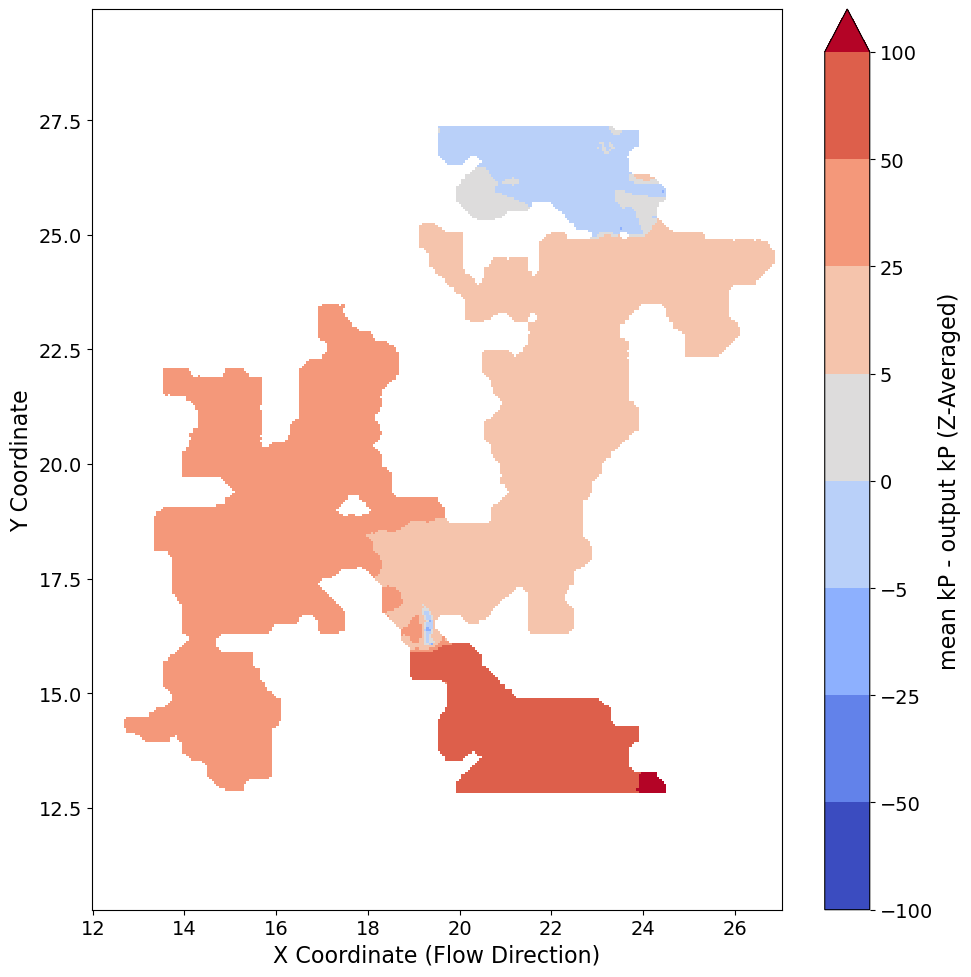

In [31]:
# ds_masked_U = ds_masked.where( ds_masked["U_mean"] > ds_masked["U_mean"].max()*0.70 )
ds_masked_p = (ds_masked['p_mean'] - kinematic_P_outlet_list[P_outlet_index])/(Kp_inlet- kinematic_P_outlet_list[P_outlet_index]) *100 
ds_2d_p = ds_masked_p.mean(dim="z")

plot_var = 'p_mean' 

# Create the plot
plt.figure(figsize=(10, 10))

# Xarray's built-in plotting automatically handles the X and Y axes

#ds_2d['p_mean'].plot(cmap='tab10')

ds_2d_p.plot(
    cmap='coolwarm',levels=[-100,-50,-25,-5,0,5,25,50,100],extend='max',   
    cbar_kwargs={'label': 'mean kP - output kP (Z-Averaged)'}
)

plt.xlabel("X Coordinate (Flow Direction)")
plt.ylabel("Y Coordinate")

plt.axis('equal')          # Ensures the aspect ratio of your cavity isn't distorted
#plt.ylim(5,25)
plt.tight_layout()

plt.show()

Flood stopped growing at iteration 2. Constriction reached!


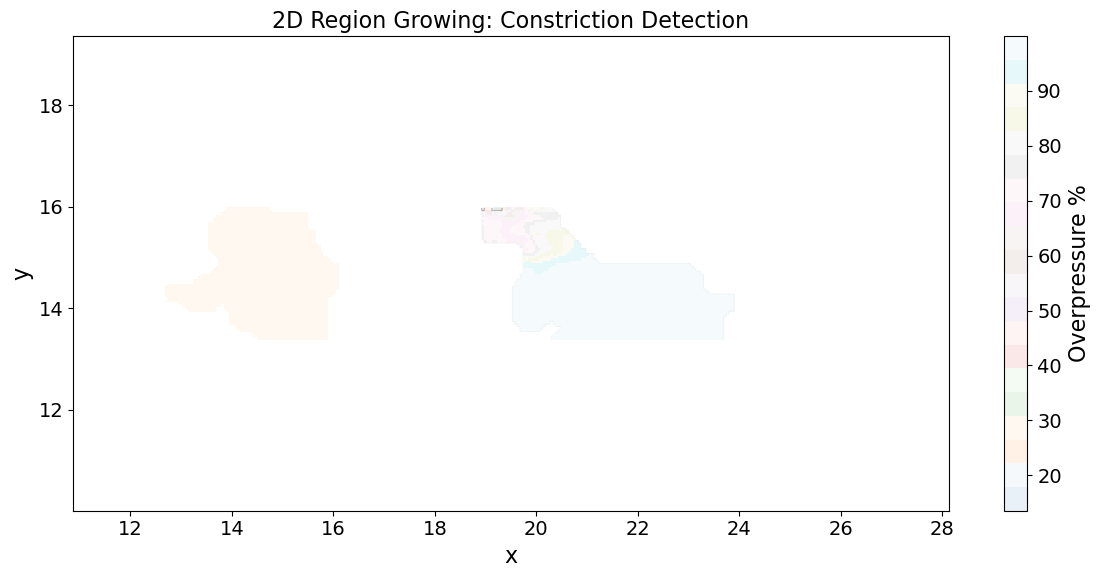

In [32]:
ds_cropped = ds_2d_p.sel(y=slice(13.4, 16.0))
grown_region, constriction_interface = f.find_2d_constriction_by_dilation(ds_cropped, start_p=50.0, stop_p=22.0, periodic_Y=False)

plt.figure(figsize=(12, 6))


ds_cropped.plot(cmap='tab20', alpha=0.1, cbar_kwargs={'label': 'Overpressure %'})


region_plot = np.where(grown_region, 1.0, np.nan)
plt.imshow(region_plot, extent=[ds_cropped.x.min(), ds_cropped.x.max(), ds_cropped.y.min(), ds_cropped.y.max()], 
           origin='lower', cmap='Greys', alpha=0.10)


interface_plot = np.where(constriction_interface, 1.0, np.nan)
plt.imshow(interface_plot, extent=[ds_cropped.x.min(), ds_cropped.x.max(), ds_cropped.y.min(), ds_cropped.y.max()], 
           origin='lower', cmap='Reds')

plt.title("2D Region Growing: Constriction Detection")
plt.axis('equal')
plt.tight_layout()
plt.show()


--- FINAL CONSTRICTION METRICS ---
Absolute Minimum Area: 0.3021 m²
with a perimeter of : 3.3230 m
Geometric Center: X=15.4582, Y=15.0818, Z=-0.5000


/home/grandafe/Documents/Stage/code/cavity_functions_cyclic.py:1379: UserWarning: Using static image for notebook display.
Install trame for interactive backends: pip install "pyvista[jupyter]"
  plotter.show()


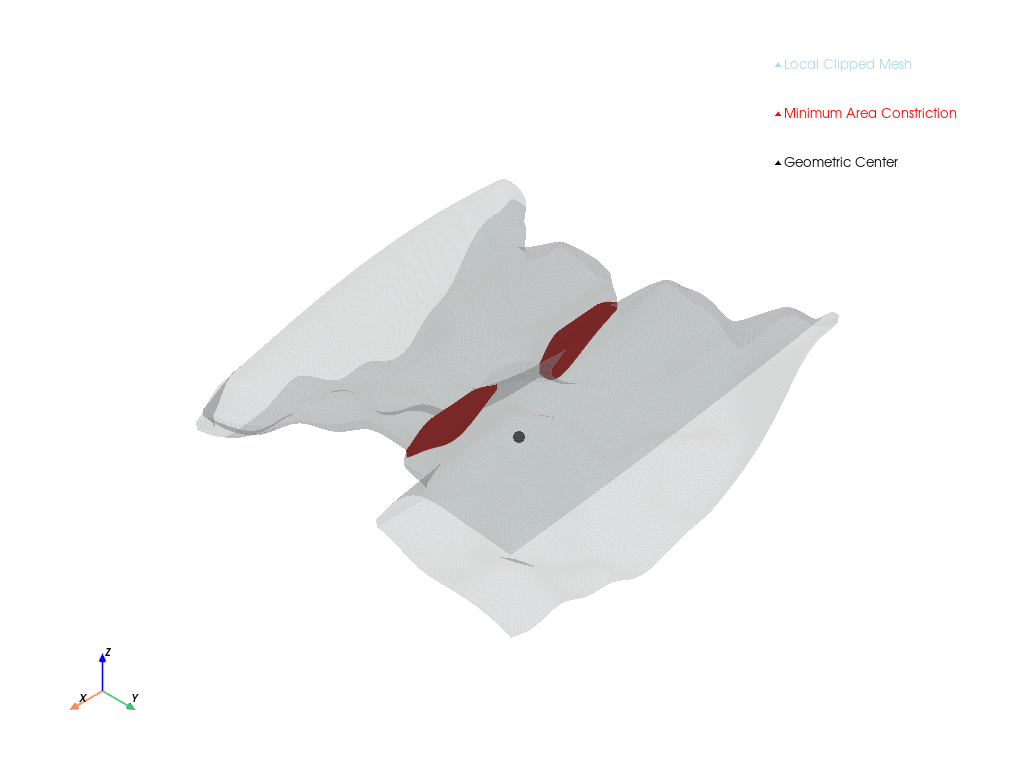

In [34]:
seed_origin, normal = f.get_plane_from_interface(ds_cropped, constriction_interface)
seed_origin[2]= -0.5
# Run the Geometric Sweep
results = f.find_minimum_area_from_stl(
    stl_file_name=file_name_pp,
    seed_origin=seed_origin,
    normal=normal,
    sweep_dist=-0.3,  # Sweep distance
    num_planes=80,    # High resolution sweep
    box_size=1.50     # Clip a  box around the seed
)


if results:
    print("\n--- FINAL CONSTRICTION METRICS ---")
    print(f"Absolute Minimum Area: {results['min_area']:.4f} m²")
    print(f"with a perimeter of : {results['min_perimeter']:.4f} m")
    print(f"Geometric Center: X={results['best_origin'][0]:.4f}, "
          f"Y={results['best_origin'][1]:.4f}, Z={results['best_origin'][2]:.4f}")
    f.visualize_constriction(results)

In [35]:
G_r_h_lim = np.sqrt(results['min_area']**3/results['min_perimeter'])
G_r_h_lim

np.float64(0.09108090708901559)


--- FINAL CONSTRICTION METRICS ---
Absolute Minimum Area: 0.3943 m²
with a perimeter of : 4.4889 m
Geometric Center: X=22.2791, Y=14.5413, Z=-0.5000


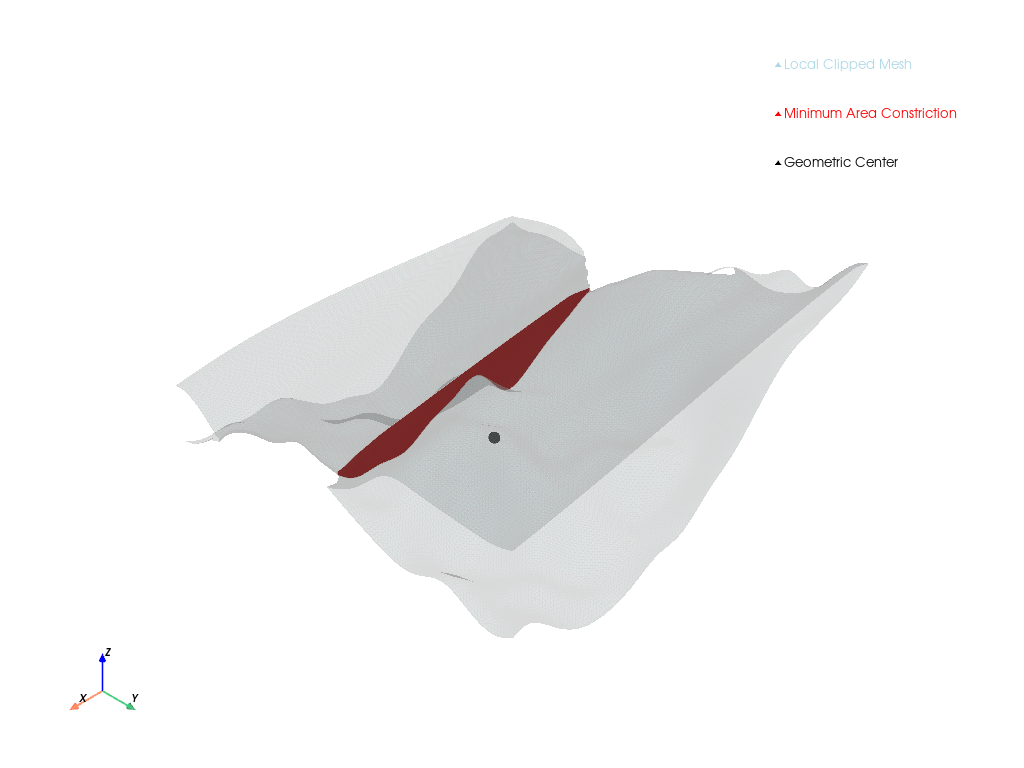

In [36]:
results_theo = f.find_minimum_area_from_stl(
    stl_file_name='sinus3dnS_1_14_70_0065__t0002_trsh_1',
    seed_origin=[22.276,14.697,-0.5],
    normal=[-0.02,0.99,0],
    sweep_dist=-0.3,  # Sweep distance
    num_planes=80,    # High resolution sweep
    box_size=1.4     # Clip a  box around the seed
)

if results_theo:
    print("\n--- FINAL CONSTRICTION METRICS ---")
    print(f"Absolute Minimum Area: {results_theo['min_area']:.4f} m²")
    print(f"with a perimeter of : {results_theo['min_perimeter']:.4f} m")
    print(f"Geometric Center: X={results_theo['best_origin'][0]:.4f}, "
          f"Y={results_theo['best_origin'][1]:.4f}, Z={results_theo['best_origin'][2]:.4f}")
    f.visualize_constriction(results_theo)

In [37]:
G_r_theo = np.sqrt(results_theo['min_area']**3/results_theo['min_perimeter'])
G_r_theo

np.float64(0.11686957627588579)

In [38]:
file_name_pp

'sinus3dnS_1_14_70_0065__t0002_trsh_15'

In [10]:
SS_startTime = 5000

#initialise the flowrate_df :
main_flowrate_df = None
init_dir = '621'
P_out_val_init=str(f'_kPout_{init_dir}')
directory_name_init=f'3D_cavity_{theta_nb_pp}_trsh_{trsh_str_pp}'+P_out_val_init

flowrate_df_init = f.get_flow_rates(directory_name_init,theta_nb_pp,trsh_str_pp,P_out_val_init,merge = True,files_to_merge=[0,3000])
main_flowrate_df = flowrate_df_init



#for i,kP_out in enumerate(kinematic_P_outlet_list):
for i,kP_out in enumerate(kinematic_P_outlet_list):
    Full_ds = {}
    P_out_val_it=str(f'_kPout_{kP_out:.0f}')
    print(f'--- processing the simulation for kP_out of {kP_out:.0f} m2/s2 ---\n')
    directory_name_it=f'3D_cavity_{theta_nb_pp}_trsh_{trsh_str_pp}'+P_out_val_it
    file_name_post_it = file_name_pp+P_out_val_it
    
    #Full_ds[f'trsh_{trsh_str_pp}{P_out_val_it}'] = f.get_sim_data(directory_name_it,theta_nb_pp,trsh_str_pp,b_coords,save=True,mean_val=True,yPlus=False,res=0.05,filename_save=file_name_post_it)
    
    if P_out_val_it == P_out_val_init :
        continue
    else :
        flowrate_df = f.get_flow_rates(directory_name_it,theta_nb_pp,trsh_str_pp,P_out_val_it,merge = True,files_to_merge=[3000,4500])
    

    main_flowrate_df = main_flowrate_df.join(flowrate_df.set_index("Time"), on="Time",how="outer")


main_flowrate_df_SS = main_flowrate_df[main_flowrate_df['Time'] >=SS_startTime].set_index('Time')
main_flowrate_df = main_flowrate_df.set_index('Time')

# Create a list of column names sorted by the numeric value at the end (descending)
sorted_cols = sorted(
    main_flowrate_df.columns, 
    key=lambda x: float(x.split('_')[-1]), 
    reverse=True
)

# Reorder the dataframe using this sorted list
main_flowrate_df = main_flowrate_df[sorted_cols]
main_flowrate_df_SS = main_flowrate_df_SS[sorted_cols]

flowrate_filename_save = f'flowrate_{file_name_pp}'
main_flowrate_df.to_csv(f'/home/grandafe/Documents/Stage/post_sim_data/{theta_nb_pp}/trsh_{trsh_str_pp}/{flowrate_filename_save}.csv')


--- processing the simulation for kP_out of 630 m2/s2 ---

--- processing the simulation for kP_out of 626 m2/s2 ---

--- processing the simulation for kP_out of 621 m2/s2 ---

--- processing the simulation for kP_out of 612 m2/s2 ---

--- processing the simulation for kP_out of 602 m2/s2 ---

--- processing the simulation for kP_out of 593 m2/s2 ---

--- processing the simulation for kP_out of 584 m2/s2 ---

--- processing the simulation for kP_out of 575 m2/s2 ---

--- processing the simulation for kP_out of 566 m2/s2 ---

--- processing the simulation for kP_out of 557 m2/s2 ---

--- processing the simulation for kP_out of 548 m2/s2 ---

--- processing the simulation for kP_out of 539 m2/s2 ---

--- processing the simulation for kP_out of 489 m2/s2 ---



In [85]:
# 1. Define your specific start times for each simulation
fine_flowrate_df_SS = None
SS_start_times = {
    'FlowRate_kPout_489': 14000,  # <-- Change this to whatever 489 needs
    'FlowRate_kPout_630': 8000,
    'FlowRate_kPout_621': 8000
}

# 2. INITIALISE (Full data)
P_out_val_init = f'_kPout_{489:.0f}'
directory_name_init = f'fine_3D_cavity_{theta_nb_pp}_trsh_{trsh_str_pp}{P_out_val_init}'

fine_flowrate_df = f.get_flow_rates(
    directory_name_init, theta_nb_pp, trsh_str_pp, P_out_val_init, 
    merge=True, files_to_merge=[6000, 9000]
)

# 3. LOOP THROUGH NEW SIMULATIONS (Full data)
for i, kP_out in enumerate([630, 621]):
    P_out_val_it = f'_kPout_{kP_out:.0f}'
    print(f'--- processing the simulation for kP_out of {kP_out:.0f} m2/s2 ---\n')
    
    directory_name_it = f'fine_3D_cavity_{theta_nb_pp}_trsh_{trsh_str_pp}{P_out_val_it}'
    tmp_flowrate_df = f.get_flow_rates(
        directory_name_it, theta_nb_pp, trsh_str_pp, P_out_val_it, 
        merge=True, files_to_merge=[6000, 9000]
    )

    # Join full data
    fine_flowrate_df = fine_flowrate_df.join(tmp_flowrate_df.set_index("Time"), on="Time", how="outer")

# Set index for the full dataframe
fine_flowrate_df = fine_flowrate_df.set_index('Time')

# 4. CREATE STEADY STATE DATAFRAME
fine_flowrate_df_SS = fine_flowrate_df.copy()

# Loop through our dictionary and mask out the early times for each column
for col, start_time in SS_start_times.items():
    if col in fine_flowrate_df_SS.columns:
        # Keep values where index (Time) >= start_time, otherwise turn to NaN
        mask = fine_flowrate_df_SS.index >= start_time
        fine_flowrate_df_SS[col] = fine_flowrate_df_SS[col].where(mask)

# Optional: Drop rows where ALL simulations are NaN (e.g., if nothing is steady-state before Time=3000)
fine_flowrate_df_SS = fine_flowrate_df_SS.dropna(how='all')

--- processing the simulation for kP_out of 630 m2/s2 ---

--- processing the simulation for kP_out of 621 m2/s2 ---



In [86]:
fine_flowrate_df_SS

,FlowRate_kPout_489,FlowRate_kPout_630,FlowRate_kPout_621
Time,,,
8000,NaN,0.175751,0.465917
8001,NaN,0.175747,0.465909
8002,NaN,0.175743,0.465900
8003,NaN,0.175740,0.465893
8004,NaN,0.175736,0.465885
...,...,...,...
14996,1.506367,NaN,NaN
14997,1.506483,NaN,NaN
14998,1.506600,NaN,NaN


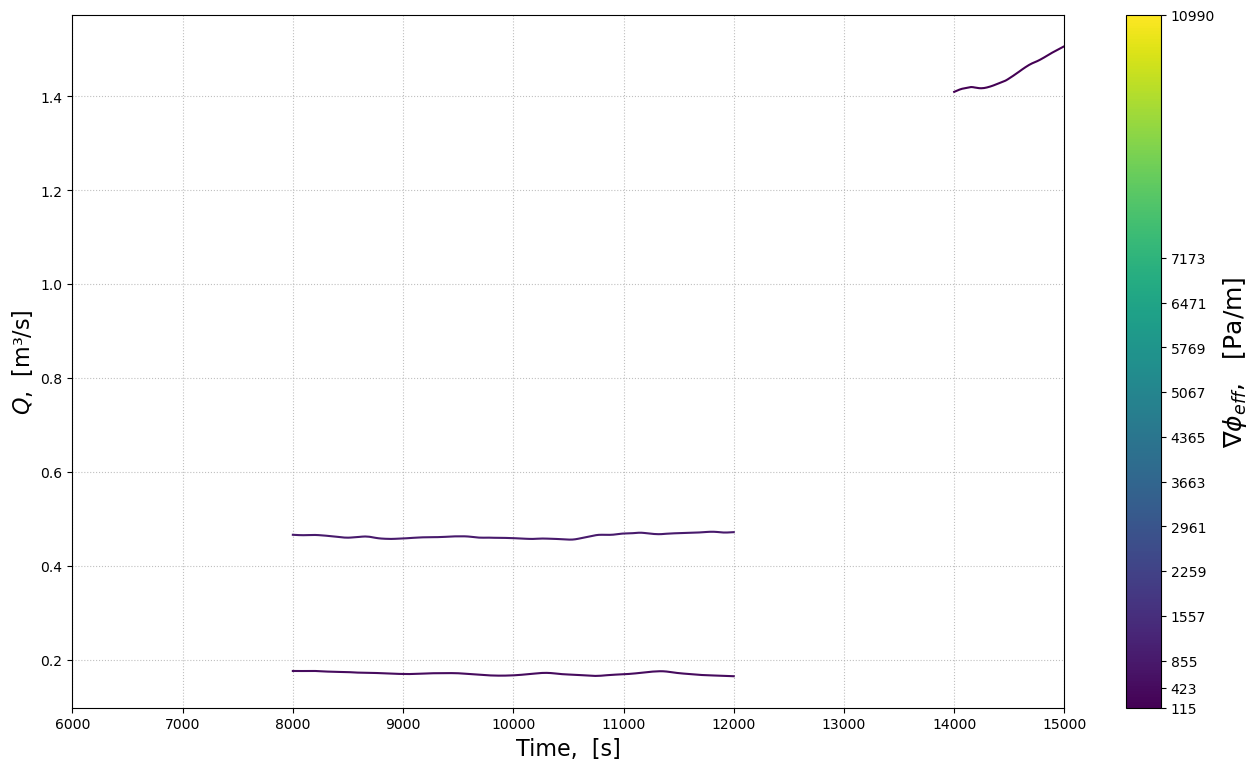

In [87]:
# 1. Map the normalization directly to the min/max of your gradient list
vmin = grad_eff_phi_list[0]
vmax = grad_eff_phi_list[-1]

num_cols = len(fine_flowrate_df_SS.columns)
cmap = plt.get_cmap('viridis') 
norm = Normalize(vmin=vmin, vmax=vmax)

fig, ax = plt.subplots(figsize=(16, 9))


for i, column in enumerate(fine_flowrate_df_SS):
    # Get the actual value for the current column
    phi_val = grad_eff_phi_list[i]
    
    # Get the ramped color based on the actual value, not the loop index
    color = cmap(norm(phi_val))
    
    # legend=False stops Pandas from fighting you over the legend generation
    fine_flowrate_df_SS[column].plot(ax=ax, color=color, legend=False)

# Vertical line
plt.axvline(SS_startTime, linestyle='--', color='k')

# Labels and grid
plt.ylabel(r'$Q$,  [m³/s]', fontsize=16)
plt.xlabel(r'Time,  [s]', fontsize=16)
plt.grid(alpha=0.8, linestyle=':')

# 2. Create the colorbar matching the grad_eff_phi_list values
sm = plt.cm.ScalarMappable(cmap=cmap, norm=norm)
sm.set_array([])  # Dummy array for the ScalarMappable

cbar = fig.colorbar(sm, ax=ax, ticks=grad_eff_phi_list)
cbar.set_label(r'$\nabla \phi_{eff}$,   [Pa/m]', fontsize=18)
plt.xlim(6000,15000)
#plt.ylim(-0.25,1.5)
#plt.savefig('/home/grandafe/Documents/Stage/img/point_23_06/flowrate_time_ss.png')
plt.show()

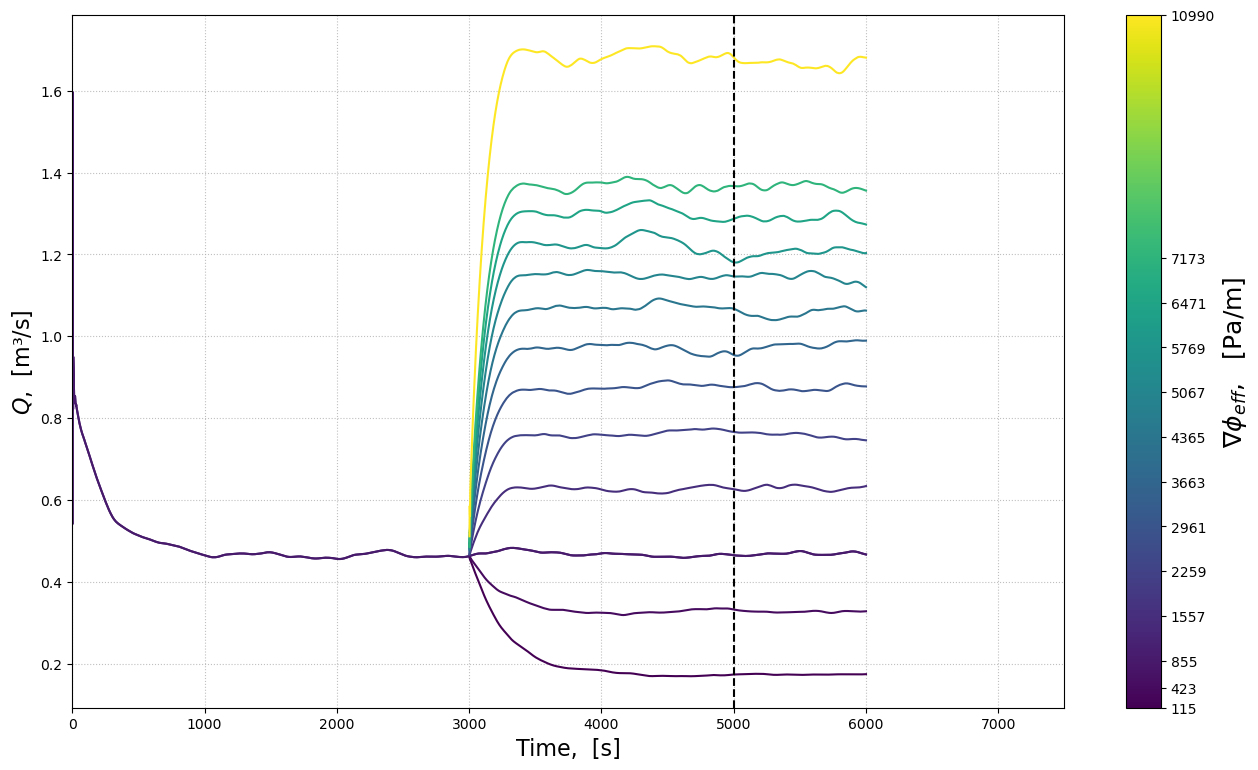

In [88]:
# 1. Map the normalization directly to the min/max of your gradient list
vmin = grad_eff_phi_list[0]
vmax = grad_eff_phi_list[-1]

num_cols = len(main_flowrate_df.columns)
cmap = plt.get_cmap('viridis') 
norm = Normalize(vmin=vmin, vmax=vmax)

fig, ax = plt.subplots(figsize=(16, 9))


main_flowrate_df['FlowRate_kPout_621'].plot(ax=ax, color=cmap(norm(grad_eff_phi_list[2])), legend=False)
for i, column in enumerate(main_flowrate_df):
    # Get the actual value for the current column
    phi_val = grad_eff_phi_list[i]
    
    # Get the ramped color based on the actual value, not the loop index
    color = cmap(norm(phi_val))
    
    # legend=False stops Pandas from fighting you over the legend generation
    main_flowrate_df[column].plot(ax=ax, color=color, legend=False)

# Vertical line
plt.axvline(SS_startTime, linestyle='--', color='k')

# Labels and grid
plt.ylabel(r'$Q$,  [m³/s]', fontsize=16)
plt.xlabel(r'Time,  [s]', fontsize=16)
plt.grid(alpha=0.8, linestyle=':')

# 2. Create the colorbar matching the grad_eff_phi_list values
sm = plt.cm.ScalarMappable(cmap=cmap, norm=norm)
sm.set_array([])  # Dummy array for the ScalarMappable

cbar = fig.colorbar(sm, ax=ax, ticks=grad_eff_phi_list)
cbar.set_label(r'$\nabla \phi_{eff}$,   [Pa/m]', fontsize=18)
plt.xlim(0,7500)
#plt.ylim(-0.25,1.5)
#plt.savefig('/home/grandafe/Documents/Stage/img/point_23_06/flowrate_time_ss.png')
plt.show()

In [102]:
SS_mean_flowrate = []
for column in main_flowrate_df_SS:
    SS_mean_flowrate.append(main_flowrate_df_SS[column].mean())

main_flowrate_df_SS_vs_std = [main_flowrate_df_SS["FlowRate_kPout_630"].std(),main_flowrate_df_SS["FlowRate_kPout_621"].std()]
SS_mean_flowrate_vs= [SS_mean_flowrate[0],SS_mean_flowrate[2]]

SS_mean_fine_flowrate = []
SS_std_fine_flowrate = []

for column in fine_flowrate_df_SS:
    if column == 'FlowRate_kPout_489':
        continue
    SS_mean_fine_flowrate.append(fine_flowrate_df_SS[column].mean())
    SS_std_fine_flowrate.append(fine_flowrate_df_SS[column].std())


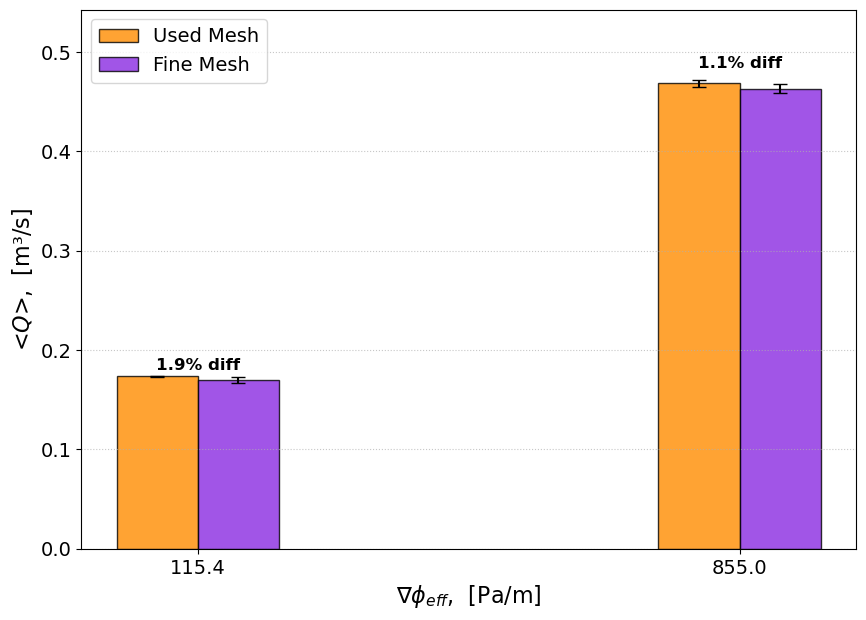

In [111]:
import numpy as np
import matplotlib.pyplot as plt


grad_phi_used = [grad_eff_phi_list[0], grad_eff_phi_list[2]]

# NOTE: Make sure your flow rate and std lists have also been sliced 
# to only contain the 2 matching values, not 3!

# Convert lists to numpy arrays for easier math
used_means = np.array(SS_mean_flowrate_vs)
used_stds = np.array(main_flowrate_df_SS_vs_std)
fine_means = np.array(SS_mean_fine_flowrate)
fine_stds = np.array(SS_std_fine_flowrate)

# Setup x locations
x = np.arange(len(grad_phi_used))  
width = 0.15                       

fig, ax = plt.subplots(figsize=(10, 7))

# Plot the bars
rects1 = ax.bar(x - width/2, used_means, width, 
                yerr=used_stds, 
                label='Used Mesh', color='darkorange', 
                capsize=5, alpha=0.8, edgecolor='black')

rects2 = ax.bar(x + width/2, fine_means, width, 
                yerr=fine_stds, 
                label='Fine Mesh', color='blueviolet', 
                capsize=5, alpha=0.8, edgecolor='black')

# 2. ADD THE % DIFFERENCE TEXT
for i in range(len(grad_phi_used)):
    # Calculate relative difference: |Fine - Used| / Used * 100
    diff_pct = abs(fine_means[i] - used_means[i]) / used_means[i] * 100
    
    # Find the highest point (bar height + error bar) to place the text above it
    max_height = max(used_means[i] + used_stds[i], fine_means[i] + fine_stds[i])
    
    # Add a 2% vertical offset so the text doesn't overlap the error bar cap
    y_offset = max_height * 0.02 
    
    # Place the text
    ax.text(x[i], max_height + y_offset, f"{diff_pct:.1f}% diff", 
            ha='center', va='bottom', fontsize=12, fontweight='bold')

# Formatting
ax.set_xlabel(r'$\nabla\phi_{eff}$,  [Pa/m]', fontsize=16)
ax.set_ylabel(r'<$Q$>,  [m³/s]', fontsize=16)

ax.set_xticks(x)
ax.set_xticklabels([f"{val:.1f}" for val in grad_phi_used], fontsize=14)
ax.tick_params(axis='y', labelsize=14)

# Scale the y-axis upper limit slightly so the new text doesn't get cut off at the top
ax.set_ylim(0, max(used_means + used_stds) * 1.15)

ax.grid(axis='y', ls=':', alpha=0.7) 
ax.legend(fontsize=14, loc='upper left')

# plt.savefig('mesh_sensitivity_barchart.png', dpi=300, bbox_inches='tight')
plt.show()

In [44]:
def effective_constriction_in_serie(a1,a2,pr1,pr2):
    Gr1 = np.sqrt(a1**3/pr1)
    Gr2 = np.sqrt(a2**3/pr2)
    num = Gr1 * Gr2
    dem = np.sqrt(Gr1**2 + Gr2**2)
    return num/dem


def circularity(a,pr):
    return 4*np.pi*a/pr**2


if   trsh_str_pp == '15' and  theta_nb_pp == "57": # en série so fD_eff = 2*fD
    a1, a2, pr1, pr2 = 0.056, 0.178, 1.025, 2.336
    Gr_eff = effective_constriction_in_serie(a1,a2,pr1,pr2)
    serie = True
    
elif trsh_str_pp == '15' and  theta_nb_pp == "60": # remember it has a different L  # en série so fD_eff = 2*fD
    a1, a2, pr1, pr2 = 0.134, 0.342, 1.888, 3.638
    Gr_eff = effective_constriction_in_serie(a1,a2,pr1,pr2)
    serie = True

    grad_phi_list_tmp = grad_eff_phi_list_for_60
    
elif trsh_str_pp == '15' and  theta_nb_pp == "65": # en série N=2 so fD_eff = 2*fD
    a1, a2, pr1, pr2 = 0.211, 0.294, 2.064, 3.481
    Gr_eff = effective_constriction_in_serie(a1,a2,pr1,pr2)
    serie = True
    
elif trsh_str_pp == '15' and  theta_nb_pp == "70":
    a1, pr1 = 0.303,3.330
    Gr_eff = np.sqrt(a1**3/pr1)
    xi_circularity = circularity(a1,pr1)

elif trsh_str_pp == '10' and  theta_nb_pp == "70":
    a1, pr1 = 0.392,4.413
    Gr_eff = np.sqrt(a1**3/pr1)
    xi_circularity = circularity(a1,pr1)
    
elif trsh_str_pp == '15' and  theta_nb_pp == "75":
    a1, pr1 = 0.342,3.500
    Gr_eff = np.sqrt(a1**3/pr1)
    xi_circularity = circularity(a1,pr1)
    
elif trsh_str_pp == '15' and  theta_nb_pp == "80":
    a1, pr1 = 0.361,3.901
    Gr_1 = np.sqrt(a1**3/pr1)
    a2, pr2 = 0.210,2.115
    Gr_2 = np.sqrt(a2**3/pr2)
    a3, pr3 = 0.037,0.754
    Gr_3 = np.sqrt(a3**3/pr3)
    Gr_eff = Gr_1 + Gr_2 + Gr_3

geo_ratio=Gr_eff
print(geo_ratio)
print(xi_circularity)

0.09139908036677334
0.3433713259341169


In [45]:
def fD_from_Bernoulli(flowrate,grad_phi,geo_ratio):
    rho_w=1000
    fD = 8*grad_phi*geo_ratio**2/(flowrate**2*rho_w)

    return fD


def S_f_from_Bernoulli(flowrate,grad_phi,geo_ratio,fD_0=0.02):
    rho_w=1000
    S_f =flowrate/geo_ratio * np.sqrt(rho_w*fD_0/(8*grad_phi) )

    return S_f

In [46]:
fD_list_computed = fD_from_Bernoulli(np.array(SS_mean_flowrate),np.array(grad_eff_phi_list),Gr_eff)

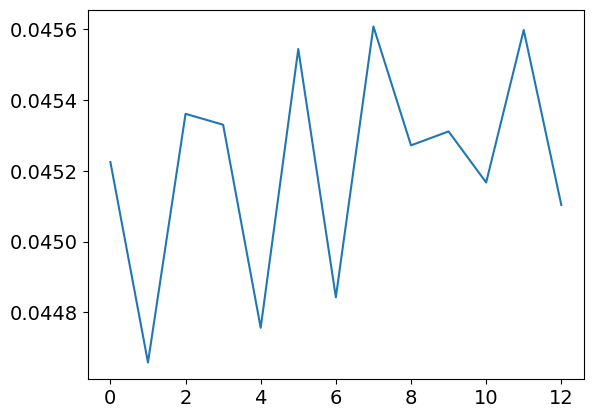

In [47]:
plt.plot(fD_list_computed)

In [48]:
fD=fD_list_computed.mean()
rho_w = 1000
fD

np.float64(0.04521376575244633)

In [49]:
# select if the adjustement variable is a or Cd :
adj = 'theta' # = 'a' ou = 'Cd'



if adj == 'fD' : # fit an fD
    
    def bernoulli_flow(x,fD):
        
        rho_w = 1000
        g_ratio=geo_ratio
        
        
        return g_ratio * np.sqrt(8*x/(rho_w*fD))

def darcy_weisbach_theta(grad_phi,theta,C1=0.0159,gamma= 0.888):
    
    rho_w = 1000
    
    return C1/(1-theta)**gamma * np.sqrt(8*grad_phi/(rho_w))

def test(theta,C1=0.0159,gamma= 0.888):
    return C1/(1-theta)**gamma 
    
#popt, pcov = curve_fit(bernoulli_flow, np.concatenate(([0],grad_eff_phi_list)),np.concatenate(([0],SS_mean_flowrate)))

In [354]:
(test(np.array(theta_list_global)) - (geometry_terms)) / (test(np.array(theta_list_global)) + (geometry_terms)) *100

array([23.10343575, -2.11199524,  9.09361678, -9.14618325,  1.56721933,
        0.11160088])

In [350]:
fitted_fD = popt[0]
print((popt[0]-fD)/(popt[0]+fD) *100)

92.28182521520809


In [351]:
popt[0], pcov

(np.float64(0.8884702829085778),
 array([[ 5.13170101e-03, -3.48384682e-04],
        [-3.48384682e-04,  2.40300782e-05]]))

In [352]:
cavitation_val
fit_coefs

array([0.88847028, 0.01591606])

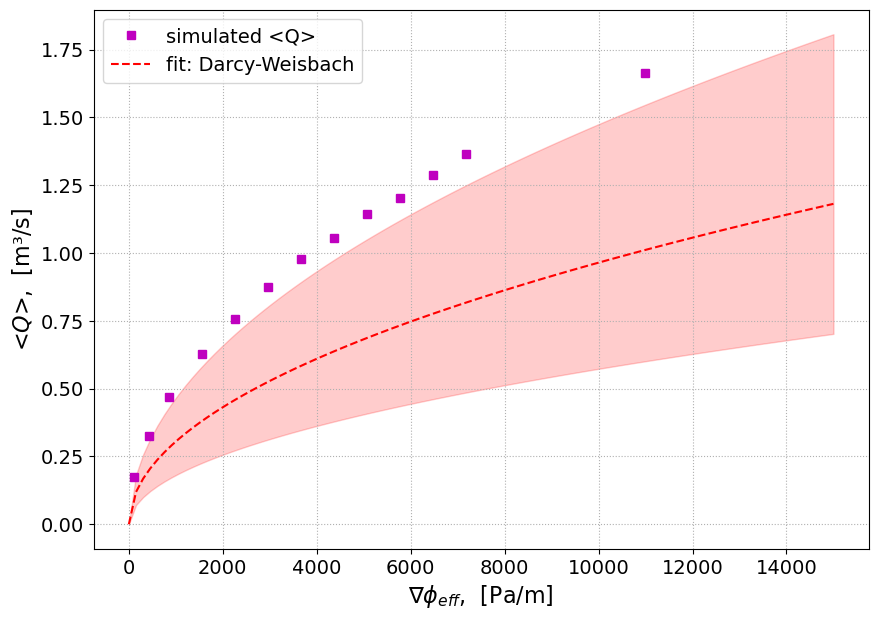

In [353]:
X = np.linspace(0, 15000, 100)
kwi_to_plot = 60

if adj == 'fD' :
    mean_fD = fD_list_computed.mean()
    uncertainty = 2*fD_list_computed.std()
    lower_bound = bernoulli_flow(X, fitted_fD - uncertainty)
    upper_bound = bernoulli_flow(X, fitted_fD + uncertainty)
else :
    lower_bound = darcy_weisbach_theta(X, cavitation_val, C1 = fit_coefs[1] - uncertainties[1], gamma = fit_coefs[0] - uncertainties[0])
    upper_bound = darcy_weisbach_theta(X, cavitation_val, C1 = fit_coefs[1] + uncertainties[1], gamma = fit_coefs[0] + uncertainties[0])


plt.figure(figsize=(10, 7))

# Plot the simulated data points
plt.plot(grad_eff_phi_list, SS_mean_flowrate, 'ms', label='simulated <Q>')


if adj == 'fD' :
     plt.plot(X, bernoulli_flow(X, fitted_fD), 'r--', 
             label=f'fit: Darcy-Weisbach, fD = {fitted_fD:.3f} ± {uncertainty:.3f}  m²·⁵')
else :
    plt.plot(X, darcy_weisbach_theta(X, cavitation_val), 'r--', 
             label=f'fit: Darcy-Weisbach')

# Add the shaded uncertainty band
plt.fill_between(X, lower_bound, upper_bound, color='red', alpha=0.2)

plt.xlabel(r'$\nabla\phi_{eff}$,  [Pa/m]', fontsize=16)
plt.ylabel(r'<$Q$>,  [m³/s]', fontsize=16)
plt.yticks(fontsize=14)
plt.xticks(fontsize=14)
plt.grid(ls=':')
plt.legend()
# plt.savefig('/home/grandafe/Documents/Stage/img/point_23_06/grad_hydrau_vs_flowrate')
plt.show()

0.03205307701809709


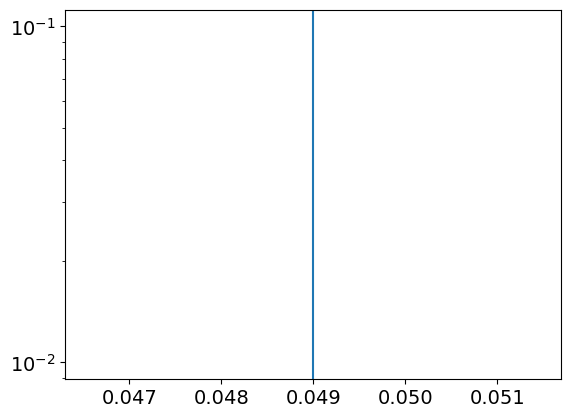

In [108]:
# Finding the sand-grain equivalent roughness 
De = 1.8 # m2
f_t = 0.049#np.linspace(0.005,0.05,100)

ks = 10**(np.log(De/2)-0.5*(1/np.sqrt(f_t)-1.74)) # chen
print(ks)
plt.semilogy(f_t,ks)
plt.axvline( 0.049 ) # chen

In [33]:
P_out_val_pp

'_kPout_621'

In [50]:
SS_startTime_1 = 5200
flowrate_dic={}
trsh_list_pp = ['10','15','25']
for trsh_str_tmp in trsh_list_pp :
    path_to_csv_flowrate = f'/home/grandafe/Documents/Stage/post_sim_data/{theta_nb_pp}/trsh_{trsh_str_tmp}/flowrate_sinus3dnS_1_14_{theta_nb_pp}_0065__t0002_trsh_{trsh_str_tmp}.csv'
    path_to_csv_Kpout = f'/home/grandafe/Documents/Stage/post_sim_data/{theta_nb_pp}/trsh_{trsh_str_tmp}/sinus3dnS_1_14_{theta_nb_pp}_0065__t0002_trsh_{trsh_str_tmp}{P_out_val_pp}.csv'
    file_name_pp_tmp = f'sinus3dnS_1_14_{theta_nb_pp}_0065__t0002_trsh_{trsh_str_tmp}'

    if trsh_str_tmp == '25':
        box_size_setting = 0.8
    else :
        box_size_setting = 1.5
    
    tmp_flowrate_df = pd.read_csv(path_to_csv_flowrate)
    tmp_flowrate_df_SS = tmp_flowrate_df[tmp_flowrate_df['Time'] >=SS_startTime_1].set_index('Time')
    flowrate_dic[f'trsh_{trsh_str_tmp}'] = tmp_flowrate_df_SS
    SS_mean_flowrate_tmp = []
    for column in tmp_flowrate_df_SS:
        SS_mean_flowrate_tmp.append(tmp_flowrate_df_SS[column].mean())
    flowrate_dic[f'mean_trsh_{trsh_str_tmp}'] = SS_mean_flowrate_tmp

    """
    tmp_kpout_df = pd.read_csv(path_to_csv_Kpout)

    ds_kpout_tmp = tmp_kpout_df.set_index(['x', 'y', 'z']).to_xarray()


    ds_kpout_tmp = (ds_kpout_tmp['p_mean'] - kinematic_P_outlet_list[P_outlet_index]) / (Kp_inlet - kinematic_P_outlet_list[P_outlet_index]) * 100 
    ds_2d_p_tmp = ds_kpout_tmp.mean(dim="z")

    grown_region, constriction_interface_tmp = f.find_2d_constriction_by_dilation(ds_2d_p_tmp, start_p=50.0, stop_p=-1.0)


    seed_origin_tmp, normal_tmp = f.get_plane_from_interface(ds_2d_p_tmp, constriction_interface_tmp)
    
    # Run the Geometric Sweep
    results = f.find_minimum_area_from_stl(
        stl_file_name=file_name_pp_tmp,
        seed_origin=seed_origin_tmp,
        normal=normal_tmp,
        sweep_dist=-0.2,  # Sweep 10cm forward
        num_planes=40,    # High resolution sweep
        box_size=box_size_setting     # Clip a nxnxn m box around the seed
    )
    
    # 3. Print the absolute truth
    if results:
        print("\n--- FINAL CONSTRICTION METRICS ---")
        print(f"Absolute Minimum Area: {results['min_area']:.6f} m²")
        print(f"Geometric Center: X={results['best_origin'][0]:.4f}, "
              f"Y={results['best_origin'][1]:.4f}, Z={results['best_origin'][2]:.4f}")
        f.visualize_constriction(results)
        """

In [51]:
flowrate_dic['mean_trsh_10']

[np.float64(0.602990522721598),
 np.float64(1.1493697103620475),
 np.float64(1.6004941785268414),
 np.float64(2.181912210986267),
 np.float64(2.6427396142322093),
 np.float64(3.0690032209737828),
 np.float64(3.3326887415730337),
 np.float64(3.6473691747815233),
 np.float64(4.0068295418227216),
 np.float64(4.158652759051186),
 np.float64(4.531189188514357),
 np.float64(4.773008996254681),
 np.float64(5.767594606741573)]

In [52]:
def bernoulli_flow_fD(x,g_ratio,fD):
        rho_w = 1000
        
        return g_ratio * np.sqrt(8*x/(rho_w*fD))

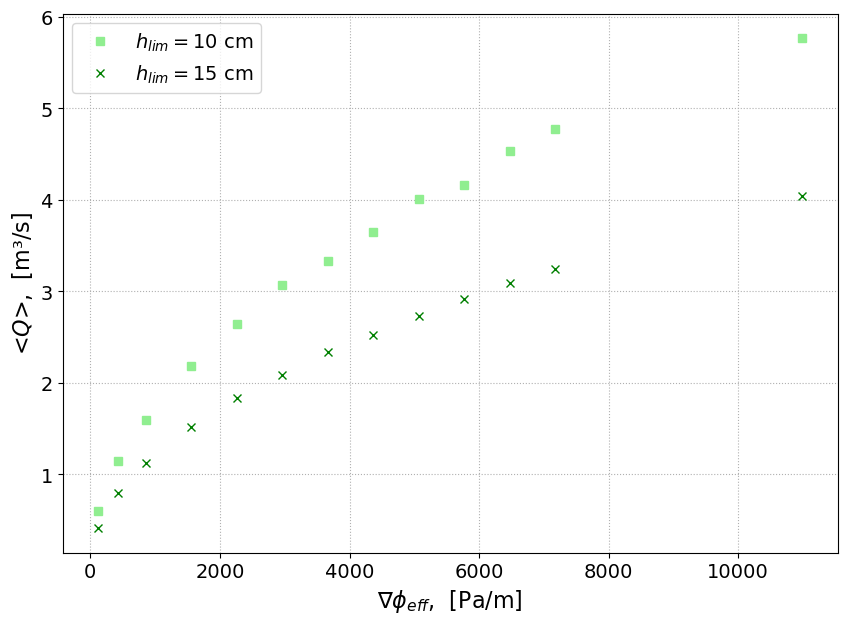

In [65]:
X1 = np.linspace(0, 12000, 100)

plt.figure(figsize=(10,7))
#plt.plot(grad_eff_phi_list,SS_mean_flowrate_fine_c,'ks')

plt.plot(grad_eff_phi_list,flowrate_dic[f'mean_trsh_{trsh_list_pp[0]}'],'s',color='lightgreen',label=r'$h_{lim}=10$ cm')
plt.plot(grad_eff_phi_list,flowrate_dic[f'mean_trsh_{trsh_list_pp[1]}'],'gx',label=r'$h_{lim}=15$ cm')
#plt.plot(grad_eff_phi_list,flowrate_dic[f'mean_trsh_{trsh_list_pp[2]}'],'rs',label=f'trsh_{trsh_list_pp[2]}')



plt.xlabel(r'$\nabla\phi_{eff}$,  [Pa/m]',fontsize=16)
plt.ylabel(r'<$Q$>,  [m³/s]',fontsize=16)
plt.yticks(fontsize=14)
plt.xticks(fontsize=14)
plt.grid(ls=':')
plt.legend()
#plt.savefig('/home/grandafe/Documents/Stage/img/point_23_06/grad_hydrau_vs_flowrate')
plt.show()

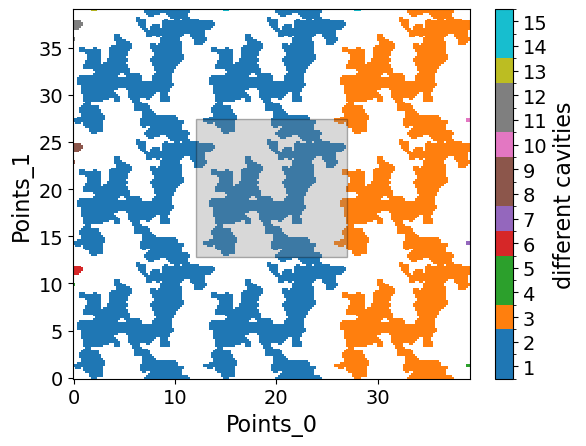

is this domain correct ? y/n ?
[12.0, 27.0, 12.8, 27.4]


KeyboardInterrupt: Interrupted by user

In [170]:
cavitation_pressure_list_pp = np.arange(51,81,1)
trsh_pp = 0.10

for cav_pressure in cavitation_pressure_list_pp :
    filename_chosen_tmp = 'sinus3dnS_1_14_'+str(cav_pressure)+'_0065__t0002'
    path_name_tmp='../data/sinus3dnS_1_14_0065/'+filename_chosen_tmp+'.csv'
    data_chosen_tmp=pd.read_csv(path_name_tmp)

    trsh_str = str(int(trsh_pp*100))
    file_name_tmp=filename_chosen_tmp+'_trsh_'+trsh_str
    
    data_tmp, data_filtered_tmp = f.filter_data(data_chosen_tmp, threshold=trsh_pp, file_name=filename_chosen_tmp, save=False, clip=False, rolling=True, knob_Pts=[0,0])
    body_dic, b_coords = f.create_surface_mesh(data_filtered,b_coords = box_coords_setup,save=False, file_name=file_name_tmp, threshold=trsh_pp,choose_1_body=False)

In [56]:
0.22+0.37+0.04

0.63

In [171]:
tau_b_list_global = []
N_list_global = []
for i in [57,60,65,70,75,80] :
    tau_b_list_global.append(all_the_other_values['tau_b'][i])
    N_list_global.append(all_the_other_values['N_norm'][i])

a_min_list_global = [0.053,0.11,0.16,0.26,0.31,0.59]
theta_list_global = [0.87,0.90,0.95,0.97,0.98,0.99]

def theta_2_a_law(x,alpha,beta):
    
    return beta*1/((1-x)**alpha )


popt, pcov = curve_fit(theta_2_a_law,theta_list_global,a_min_list_global)

X_theta = np.linspace(0.8,0.990,100)

plt.plot(X_theta,theta_2_a_law(X_theta,popt[0],popt[1]),'g--', label = r'fit : $\beta /(1-\theta)^{\alpha}$ ' + r' $\alpha$='+f'{popt[0]:.2f}' r'; $\beta$='+f'{popt[1]:.2f}')
plt.plot(theta_list_global,a_min_list_global,'kx')

plt.xlabel(r'cavitation state $\theta$')
plt.ylabel('constriction area a [m²]')
plt.legend()

print(popt[0])
print(popt[1])
fit_coefs = popt
uncertainties = np.sqrt(np.diag(pcov)) 

In [ ]:
a_list_from_schoof = np.array(all_the_other_values['tau_b'])**3.72 *A_s*h_r / ( (1-np.array(real_cavitation_list))*2*2.5e-24*3**-3*np.array(all_the_other_values['N_norm'])**3 )

In [159]:
# computed h_r : 
h_r_from_schoof = np.array(a_min_list_global)*(1-np.array(theta_list_global))*2*2.5e-24*3**-3*np.array(N_list_global)**3 / (np.array(tau_b_list_global)**3.72*A_s)

In [160]:
# and popt[0] is h_r * cst so : 
popt[0]/h_r_from_schoof

array([10.30554873,  6.54370726,  7.98674566,  8.565139  , 10.48592799,
        8.86907296])

In [35]:
def effective_constriction_in_serie(a1,a2,pr1,pr2):
    Gr1 = np.sqrt(a1**3/pr1)
    Gr2 = np.sqrt(a2**3/pr2)
    num = Gr1 * Gr2
    dem = np.sqrt(Gr1**2 + Gr2**2)
    return num/dem

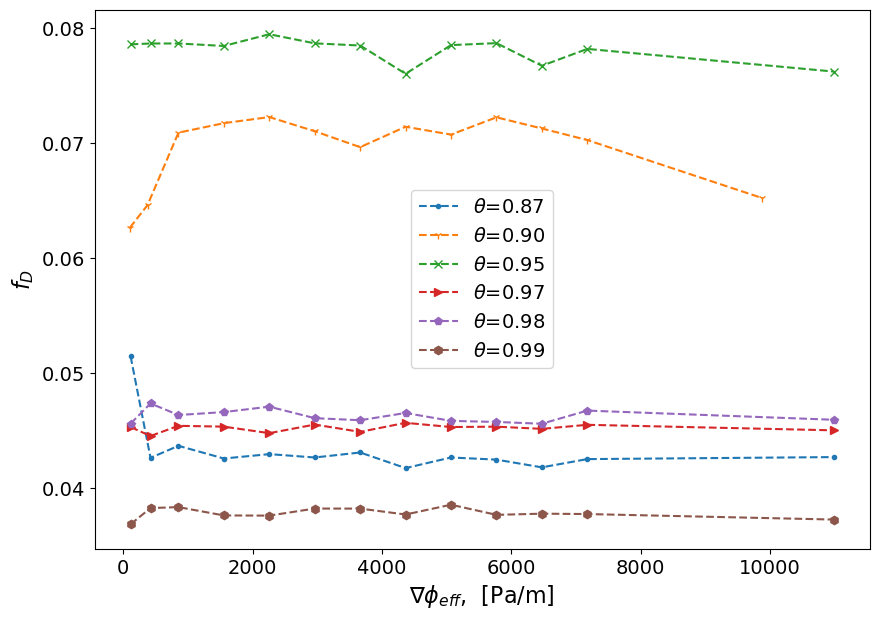

In [326]:
def fD_from_Bernoulli(flowrate,grad_phi,Gr_eff,N=1):
    rho_w=1000
    
    fD_eff = 8*grad_phi*Gr_eff**2/(flowrate**2*rho_w)
    
    return fD_eff * N


SS_startTime_1 = 5200

flowrate_dic_all_theta={}
fD_mean_list = []
fD_mean_serie_list = []
Gr_eff_list = []

linestyles = ['--.','--1','--x','-->','--p','--h']
theta_list_global = [0.87,0.90,0.95,0.97,0.98,0.99]


plt.figure(figsize=(10,7))
plt.xlabel(r'$\nabla\phi_{eff}$,  [Pa/m]',fontsize=16)
plt.ylabel(r'$f_D$',fontsize=16)

plt.yticks(fontsize=14)
plt.xticks(fontsize=14)


for j,kwi in enumerate(['57','60','65','70','75','80']) :
    path_to_csv_flow = f'/home/grandafe/Documents/Stage/post_sim_data/{kwi}/trsh_15/flowrate_sinus3dnS_1_14_{kwi}_0065__t0002_trsh_15.csv'
    
    tmp_flowrate_df = pd.read_csv(path_to_csv_flow)
    tmp_flowrate_df_SS = tmp_flowrate_df[tmp_flowrate_df['Time'] >=SS_startTime_1].set_index('Time')
    #flowrate_dic_all_theta[f'flow_Kwi_{kwi}'] = tmp_flowrate_df_SS
    SS_mean_flowrate_tmp = []
    for column in tmp_flowrate_df_SS:
        SS_mean_flowrate_tmp.append(tmp_flowrate_df_SS[column].mean())
    flowrate_dic_all_theta[f'SS_mean_flow_Kwi_{kwi}'] = SS_mean_flowrate_tmp

    grad_phi_list_tmp = grad_eff_phi_list

    serie = False


    if   trsh_str_pp == '15' and  kwi == "57": # en série so fD_eff = 2*fD
        a1, a2, pr1, pr2 = 0.056, 0.178, 1.025, 2.336
        Gr_eff = effective_constriction_in_serie(a1,a2,pr1,pr2)
        serie = True
        
    elif trsh_str_pp == '15' and  kwi == "60": # remember it has a different L  # en série so fD_eff = 2*fD
        a1, a2, pr1, pr2 = 0.134, 0.342, 1.888, 3.638
        Gr_eff = effective_constriction_in_serie(a1,a2,pr1,pr2)
        serie = True

        grad_phi_list_tmp = grad_eff_phi_list_for_60
        
    elif trsh_str_pp == '15' and  kwi == "65": # en série N=2 so fD_eff = 2*fD
        a1, a2, pr1, pr2 = 0.211, 0.294, 2.064, 3.481
        Gr_eff = effective_constriction_in_serie(a1,a2,pr1,pr2)
        serie = True
        
    elif trsh_str_pp == '15' and  kwi == "70":
        a1, pr1 = 0.303,3.330
        Gr_eff = np.sqrt(a1**3/pr1)
        
    elif trsh_str_pp == '15' and  kwi == "75":
        a1, pr1 = 0.342,3.500
        Gr_eff = np.sqrt(a1**3/pr1)
        
    elif trsh_str_pp == '15' and  kwi == "80":
        a1, pr1 = 0.361,3.901
        Gr_1 = np.sqrt(a1**3/pr1)
        a2, pr2 = 0.210,2.115
        Gr_2 = np.sqrt(a2**3/pr2)
        a3, pr3 = 0.037,0.754
        Gr_3 = np.sqrt(a3**3/pr3)
        Gr_eff = Gr_1 + Gr_2 + Gr_3

    if serie :
        flowrate_dic_all_theta[f'fD_Kwi_{kwi}']=fD_from_Bernoulli(np.array(flowrate_dic_all_theta[f'SS_mean_flow_Kwi_{kwi}']),np.array(grad_phi_list_tmp),Gr_eff,N=2)
    else :
        flowrate_dic_all_theta[f'fD_Kwi_{kwi}']=fD_from_Bernoulli(np.array(flowrate_dic_all_theta[f'SS_mean_flow_Kwi_{kwi}']),np.array(grad_phi_list_tmp),Gr_eff,N=1)
    fD_mean_list.append(flowrate_dic_all_theta[f'fD_Kwi_{kwi}'].mean())
    Gr_eff_list.append(Gr_eff)
    
    plt.plot(grad_phi_list_tmp,flowrate_dic_all_theta[f'fD_Kwi_{kwi}'],linestyles[j],label=rf'$\theta$={theta_list_global[j]:.2f}')
plt.legend()
plt.show()

In [327]:
mean_fD = np.array(fD_mean_list).mean()
margin_fD = 2*np.array(fD_mean_list).std()

print(f'fD = {mean_fD:.3e} +- {margin_fD:.3e}')




fD = 5.336e-02 +- 2.983e-02


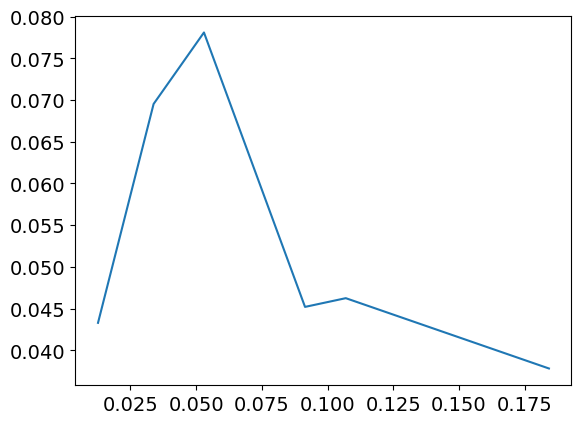

In [328]:
plt.plot(Gr_eff_list,fD_mean_list)

In [236]:
fD_mean_list

[np.float64(0.04328724769989386),
 np.float64(0.06953395321366113),
 np.float64(0.07810626939775486),
 np.float64(0.045198705667797275),
 np.float64(0.046245865850842525),
 np.float64(0.037814452964535346)]

In [329]:
Gr_eff_list

[np.float64(0.012648300525364623),
 np.float64(0.033794254526563476),
 np.float64(0.052948022800989564),
 np.float64(0.09139908036677334),
 np.float64(0.10690675242605453),
 np.float64(0.1841860278650901)]

In [334]:
geometry_terms = np.array(Gr_eff_list)/np.array(np.sqrt(fD_mean_list))
geometry_terms

array([0.06079281, 0.12815761, 0.18945532, 0.42991127, 0.49712852,
       0.94716964])

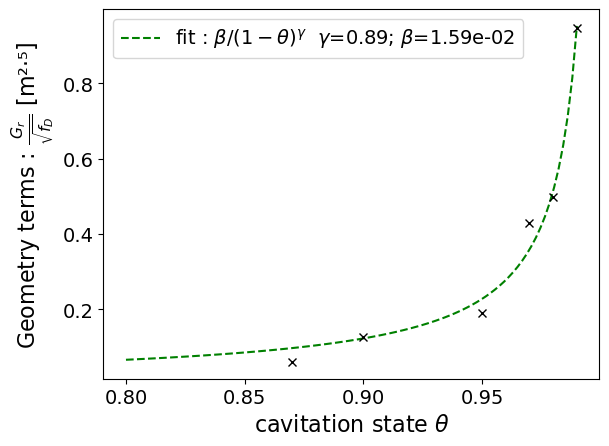

In [333]:
theta_list_global = [0.87,0.90,0.95,0.97,0.98,0.99]

def theta_2_Gr_law(x,gamma,beta1):
    
    return beta1*1/((1-x)**gamma )


popt, pcov = curve_fit(theta_2_Gr_law,theta_list_global,geometry_terms)

X_theta = np.linspace(0.8,0.990,100)

plt.plot(X_theta,theta_2_Gr_law(X_theta,popt[0],popt[1]),'g--', label = r'fit : $\beta /(1-\theta)^{\gamma}$ ' + r' $\gamma$='+f'{popt[0]:.2f}' r'; $\beta$='+f'{popt[1]:.2e}')
plt.plot(theta_list_global,np.array(Gr_eff_list)/np.array(np.sqrt(fD_mean_list)),'kx')

plt.xlabel(r'cavitation state $\theta$')
plt.ylabel(r'Geometry terms : $\frac{G_r}{\sqrt{f_D}}$ [m²·⁵]')
plt.legend()

In [279]:
pcov

array([[ 5.13170101e-03, -3.48384682e-04],
       [-3.48384682e-04,  2.40300782e-05]])

In [280]:
fit_coefs = popt
uncertainties = np.sqrt(np.diag(pcov)) 

In [105]:
Re = 0.1e5
fD_test = 0.3164*Re**(-1/4)
print(fD_test)

0.03164


In [83]:
def hydraulic_conductivity_computation(G_r_list,fD_list):
    rho_w = 1000
    alpha = 5/4
    
    k_s_h_alpha = []
    for i,G_r in enumerate(G_r_list):
        if i == 1 :
            L=14.6
        else :
            L=13.0
        k_s_h_alpha.append( 1/L * G_r * np.sqrt(8/(rho_w*fD_list[i])) )
    return k_s_h_alpha


def hydraulic_c_from_Gilbert(x):
    p1=0.6
    p2=6.5
    alpha = 5/4
    p3 = p2 + p1*alpha

    Ks0=0.1
    hr=1.0

    return Ks0*hr*x**p3

h_Ks_alpha = hydraulic_conductivity_computation(Gr_eff_list,fD_mean_list)
h_Ks_alpha_from_G = hydraulic_c_from_Gilbert(np.array(theta_list_global))

In [84]:
h_Ks_alpha_from_G

array([0.03643465, 0.0465863 , 0.06894395, 0.08018536, 0.0863752 ,
       0.09297264])

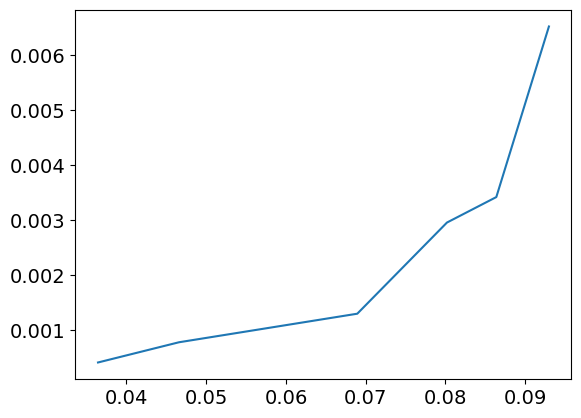

In [85]:
plt.plot(h_Ks_alpha_from_G,h_Ks_alpha)